# HR Employee Attrition — Decision Support System
## Machine Learning Pipeline + XAI Explainability

**Project Goal:** Build a robust attrition prediction system that:
- Trains multiple ML models on historical HR data
- Predicts which employees are at risk of leaving
- Explains the reasons behind each prediction (XAI)
- Exports results for HR decision-making

---
# PART 1 — Model Training Pipeline
---

## 1.1 Import Libraries

In [5]:
!pip install xgboost imbalanced-learn joblib


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
langchain-classic 1.0.8 requires langchain-core<2.0.0,>=1.4.4, but you have langchain-core 0.2.43 which is incompatible.
langchain-classic 1.0.8 requires langchain-text-splitters<2.0.0,>=1.1.2, but you have langchain-text-splitters 0.2.4 which is incompatible.
langgraph-sdk 0.4.2 requires langchain-core<2,>=1.4.0, but you have langchain-core 0.2.43 which is incompatible.
langgraph-prebuilt 1.1.0 requires langchain-core>=1.3.1, but you have langchain-core 0.2.43 which is incompatible.
langgraph 1.2.4 requires langchain-core<2,>=1.4.0, but you have langchain-core 0.2.43 which is incompatible.


In [7]:
import os
import shutil

# 1. إنشاء المجلد تلقائياً إذا لم يكن موجوداً
os.makedirs("./data_docs", exist_ok=True)

# 2. التأكد من وجود ملف الـ PDF الأصلي ونقله بالاسم الجديد المطلوب
source_file = "./Corporate_HR_Policy_Manual.pdf"
destination_file = "./data_docs/hr_policy_manual.pdf"

if os.path.exists(source_file):
    shutil.move(source_file, destination_file)
    print("✅ تم إنشاء مجلد data_docs ونقل وتعديل اسم ملف الـ PDF بنجاح!")
else:
    print("❌ لم يتم العثور على الملف بالاسم القديم، تأكدي من رفعه في المجلد الرئيسي أولاً.")


❌ لم يتم العثور على الملف بالاسم القديم، تأكدي من رفعه في المجلد الرئيسي أولاً.


  Using cached langchain_text_splitters-1.1.2-py3-none-any.whl.metadata (3.3 kB)
  Using cached langchain_community-0.4.2-py3-none-any.whl.metadata (3.4 kB)
  Using cached langchain_core-1.4.7-py3-none-any.whl.metadata (4.5 kB)
Using cached langchain_text_splitters-1.1.2-py3-none-any.whl (35 kB)
Using cached langchain_community-0.4.2-py3-none-any.whl (2.4 MB)
Using cached langchain_core-1.4.7-py3-none-any.whl (554 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 498.0/498.0 kB 11.8 MB/s eta 0:00:00
  Attempting uninstall: langsmith
    Found existing installation: langsmith 0.1.147
    Uninstalling langsmith-0.1.147:
      Successfully uninstalled langsmith-0.1.147
  Attempting uninstall: langchain-core
    Found existing installation: langchain-core 0.2.43
    Uninstalling langchain-core-0.2.43:
      Successfully uninstalled langchain-core-0.2.43
  Attempting uninstall: langchain-text-splitters
    Found existing installation: langchain-text-splitters 0.2.4
    Uninstalling langchain-

In [12]:
# Standard libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import pickle
import os
import datetime
import warnings
warnings.filterwarnings('ignore')

# Preprocessing & Modeling
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score,
    confusion_matrix, classification_report,
    precision_recall_curve
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE

print('All libraries imported successfully.')


All libraries imported successfully.


In [13]:
df = pd.read_csv('/content/IBM HR Data new.csv')
print(f'Dataset shape  : {df.shape}')
print(f'Missing values : {df.isnull().sum().sum()}')
print(f"\nAttrition distribution:")
print(df['Attrition'].value_counts())

df.head()


Dataset shape  : (23436, 37)
Missing values : 352

Attrition distribution:
Attrition
Current employee         19714
Voluntary Resignation     3709
Name: count, dtype: int64


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Employee Source
0,41.0,Voluntary Resignation,Travel_Rarely,1102.0,Sales,1,2.0,Life Sciences,1,1,...,80.0,0.0,8.0,0.0,1.0,6.0,4.0,0.0,5.0,Referral
1,41.0,Voluntary Resignation,Travel_Rarely,1102.0,Sales,1,2.0,Life Sciences,1,1,...,80.0,0.0,8.0,0.0,1.0,6.0,4.0,0.0,5.0,Referral
2,41.0,Voluntary Resignation,Travel_Rarely,1102.0,Sales,1,2.0,Life Sciences,1,7,...,80.0,0.0,8.0,0.0,1.0,6.0,4.0,0.0,5.0,Referral
3,41.0,Voluntary Resignation,Travel_Rarely,1102.0,Sales,1,2.0,Life Sciences,1,8,...,80.0,0.0,8.0,0.0,1.0,6.0,4.0,0.0,5.0,Referral
4,41.0,Voluntary Resignation,Travel_Rarely,1102.0,Sales,1,2.0,Life Sciences,1,9,...,80.0,0.0,8.0,0.0,1.0,6.0,4.0,0.0,5.0,Referral


## 1.2 Load Dataset

## 1.3 Exploratory Data Analysis (EDA)

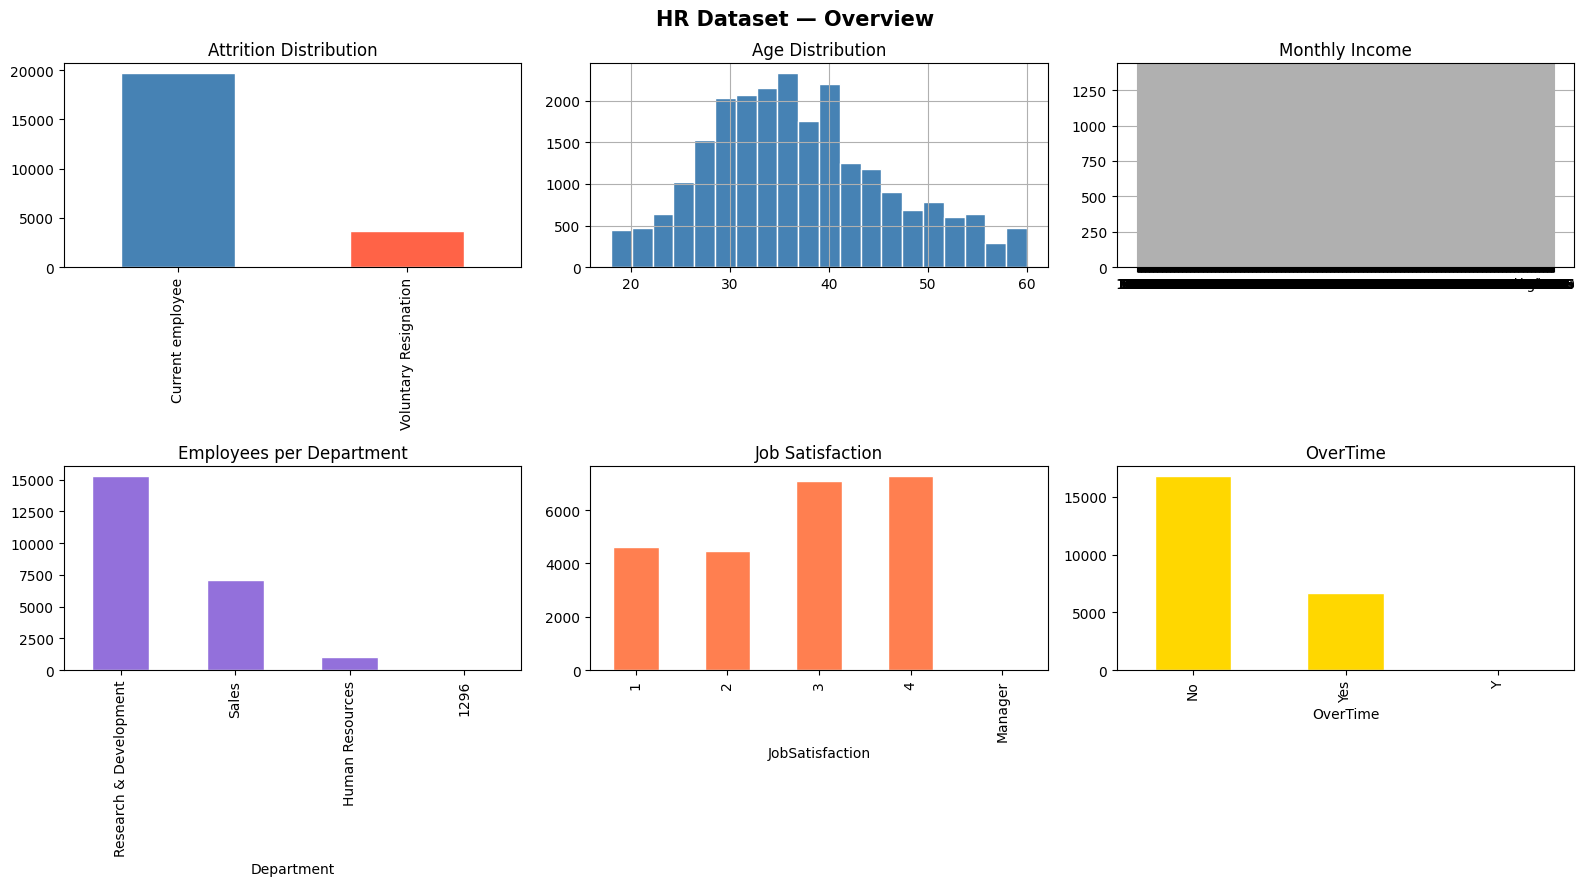

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle('HR Dataset — Overview', fontsize=15, fontweight='bold')

# Attrition count
df['Attrition'].value_counts().plot(
    kind='bar', ax=axes[0, 0], color=['steelblue', 'tomato'], edgecolor='white')
axes[0, 0].set_title('Attrition Distribution')
axes[0, 0].set_xlabel('')

# Age distribution
if 'Age' in df.columns:
    df['Age'].hist(ax=axes[0, 1], bins=20, color='steelblue', edgecolor='white')
    axes[0, 1].set_title('Age Distribution')

# Monthly income
if 'MonthlyIncome' in df.columns:
    df['MonthlyIncome'].hist(ax=axes[0, 2], bins=20, color='mediumseagreen', edgecolor='white')
    axes[0, 2].set_title('Monthly Income')

# Department
if 'Department' in df.columns:
    df['Department'].value_counts().plot(
        kind='bar', ax=axes[1, 0], color='mediumpurple', edgecolor='white')
    axes[1, 0].set_title('Employees per Department')

# Job Satisfaction
if 'JobSatisfaction' in df.columns:
    df['JobSatisfaction'].value_counts().sort_index().plot(
        kind='bar', ax=axes[1, 1], color='coral', edgecolor='white')
    axes[1, 1].set_title('Job Satisfaction')

# OverTime
if 'OverTime' in df.columns:
    df['OverTime'].value_counts().plot(
        kind='bar', ax=axes[1, 2], color='gold', edgecolor='white')
    axes[1, 2].set_title('OverTime')

plt.tight_layout()
plt.show()


## 1.4 Data Cleaning & Encoding

In [15]:
data = df.copy()

# --- Remove uninformative columns ---
drop_cols = ['EmployeeCount', 'Over18', 'StandardHours', 'EmployeeNumber']
data = data.drop(columns=[c for c in drop_cols if c in data.columns])

# --- Encode target variable (smart detection) ---
leave_keywords = ['yes', 'voluntary resignation', 'left', 'resigned', '1', 'true']
data['Attrition'] = (
    data['Attrition'].astype(str).str.strip().str.lower()
    .apply(lambda x: 1 if any(k in x for k in leave_keywords) else 0)
)
print(f"Stay (0) : {(data['Attrition'] == 0).sum()}")
print(f"Leave(1) : {(data['Attrition'] == 1).sum()}")

# --- Fill missing values (whole dataset) ---
for col in data.columns:
    if data[col].isnull().sum() > 0:
        if data[col].dtype in ['float64', 'int64']:
            data[col] = data[col].fillna(data[col].median())
        else:
            data[col] = data[col].fillna(data[col].mode()[0])

# NOTE: LabelEncoders are fitted on TRAINING data only (in section 1.8).
categorical_cols = data.select_dtypes(include=['object']).columns.tolist()
print(f"\nCategorical columns to encode: {categorical_cols}")
print(f"Cleaned data shape: {data.shape}")


Stay (0) : 19727
Leave(1) : 3709

Categorical columns to encode: ['BusinessTravel', 'Department', 'DistanceFromHome', 'EducationField', 'Application ID', 'Gender', 'HourlyRate', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'OverTime', 'PercentSalaryHike', 'Employee Source']
Cleaned data shape: (23436, 33)


## 1.5 Correlation Analysis — BEFORE Feature Engineering

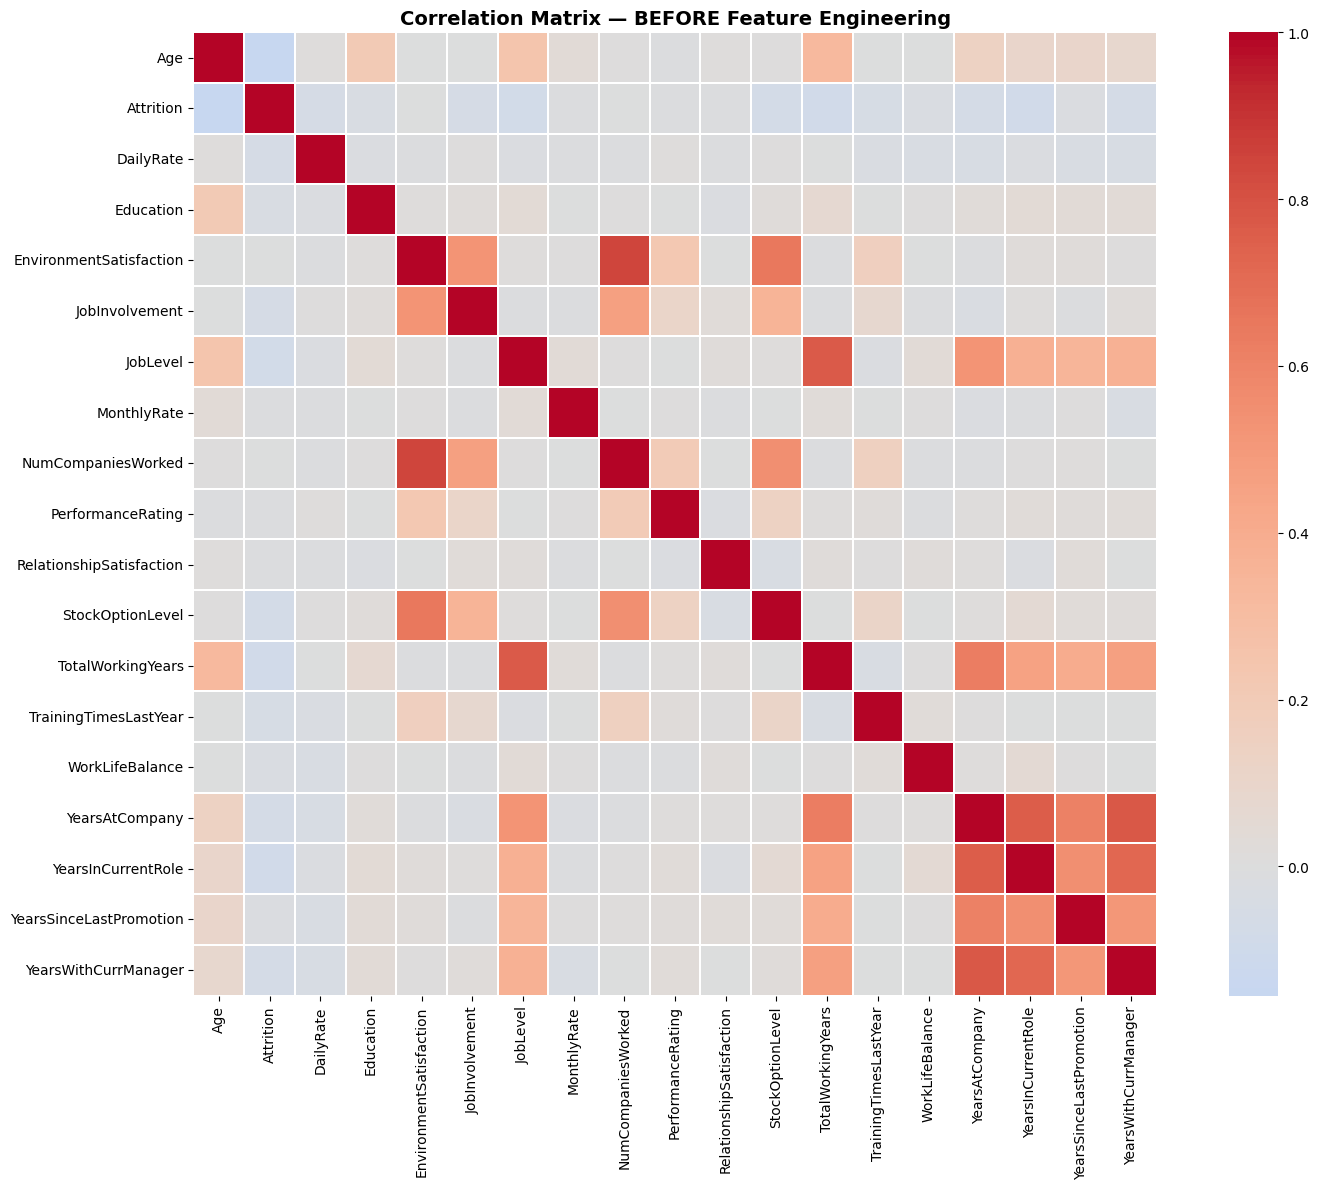

Top 10 features correlated with Attrition (BEFORE):
NumCompaniesWorked         -0.002704
EnvironmentSatisfaction    -0.004050
RelationshipSatisfaction   -0.006942
PerformanceRating          -0.007500
MonthlyRate                -0.008321
YearsSinceLastPromotion    -0.020117
WorkLifeBalance            -0.026161
Education                  -0.034861
TrainingTimesLastYear      -0.048363
DailyRate                  -0.057198
Name: Attrition, dtype: float64


In [16]:
numeric_cols_before = data.select_dtypes(include=[np.number]).columns.tolist()
corr_before = data[numeric_cols_before].corr()

plt.figure(figsize=(16, 12))
sns.heatmap(
    corr_before,
    annot=False, cmap='coolwarm', center=0,
    square=True, linewidths=0.3
)
plt.title(
    'Correlation Matrix — BEFORE Feature Engineering',
    fontsize=14, fontweight='bold'
)
plt.tight_layout()
plt.show()

print("Top 10 features correlated with Attrition (BEFORE):")
top_before = (
    corr_before['Attrition']
    .drop('Attrition')
    .sort_values(ascending=False)
)
print(top_before.head(10))


## 1.6 Feature Engineering

In [17]:
# Feature 1 — Overall Satisfaction Score
sat_cols = [
    'JobSatisfaction', 'EnvironmentSatisfaction',
    'RelationshipSatisfaction', 'WorkLifeBalance'
]
available_sat = [c for c in sat_cols if c in data.columns]
if available_sat:
    for _sc in available_sat:
        data[_sc] = pd.to_numeric(data[_sc], errors='coerce')
    data['SatisfactionScore'] = (
        data[available_sat].mean(axis=1, skipna=True).astype(float)
    )
    data['SatisfactionScore'] = data['SatisfactionScore'].fillna(
        data['SatisfactionScore'].median()
    )
    print('Created: SatisfactionScore')

# Feature 2 — Income relative to experience
if 'MonthlyIncome' in data.columns and 'TotalWorkingYears' in data.columns:
    data['IncomePerExp'] = (
        pd.to_numeric(data['MonthlyIncome'], errors='coerce') /
        (pd.to_numeric(data['TotalWorkingYears'], errors='coerce') + 1)
    )
    data['IncomePerExp'] = data['IncomePerExp'].fillna(data['IncomePerExp'].median())
    print('Created: IncomePerExp')

# Feature 3 — Company loyalty ratio
if 'YearsAtCompany' in data.columns and 'TotalWorkingYears' in data.columns:
    data['LoyaltyRatio'] = (
        pd.to_numeric(data['YearsAtCompany'], errors='coerce') /
        (pd.to_numeric(data['TotalWorkingYears'], errors='coerce') + 1)
    )
    data['LoyaltyRatio'] = data['LoyaltyRatio'].fillna(data['LoyaltyRatio'].median())
    print('Created: LoyaltyRatio')

# Feature 4 — Time since last promotion relative to tenure
if 'YearsSinceLastPromotion' in data.columns and 'YearsAtCompany' in data.columns:
    data['PromotionLag'] = (
        pd.to_numeric(data['YearsSinceLastPromotion'], errors='coerce') /
        (pd.to_numeric(data['YearsAtCompany'], errors='coerce') + 1)
    )
    data['PromotionLag'] = data['PromotionLag'].fillna(data['PromotionLag'].median())
    print('Created: PromotionLag')

print(f'\nTotal features after engineering: {data.shape[1]}')


Created: SatisfactionScore
Created: IncomePerExp
Created: LoyaltyRatio
Created: PromotionLag

Total features after engineering: 37


## 1.7 Correlation Analysis — AFTER Feature Engineering

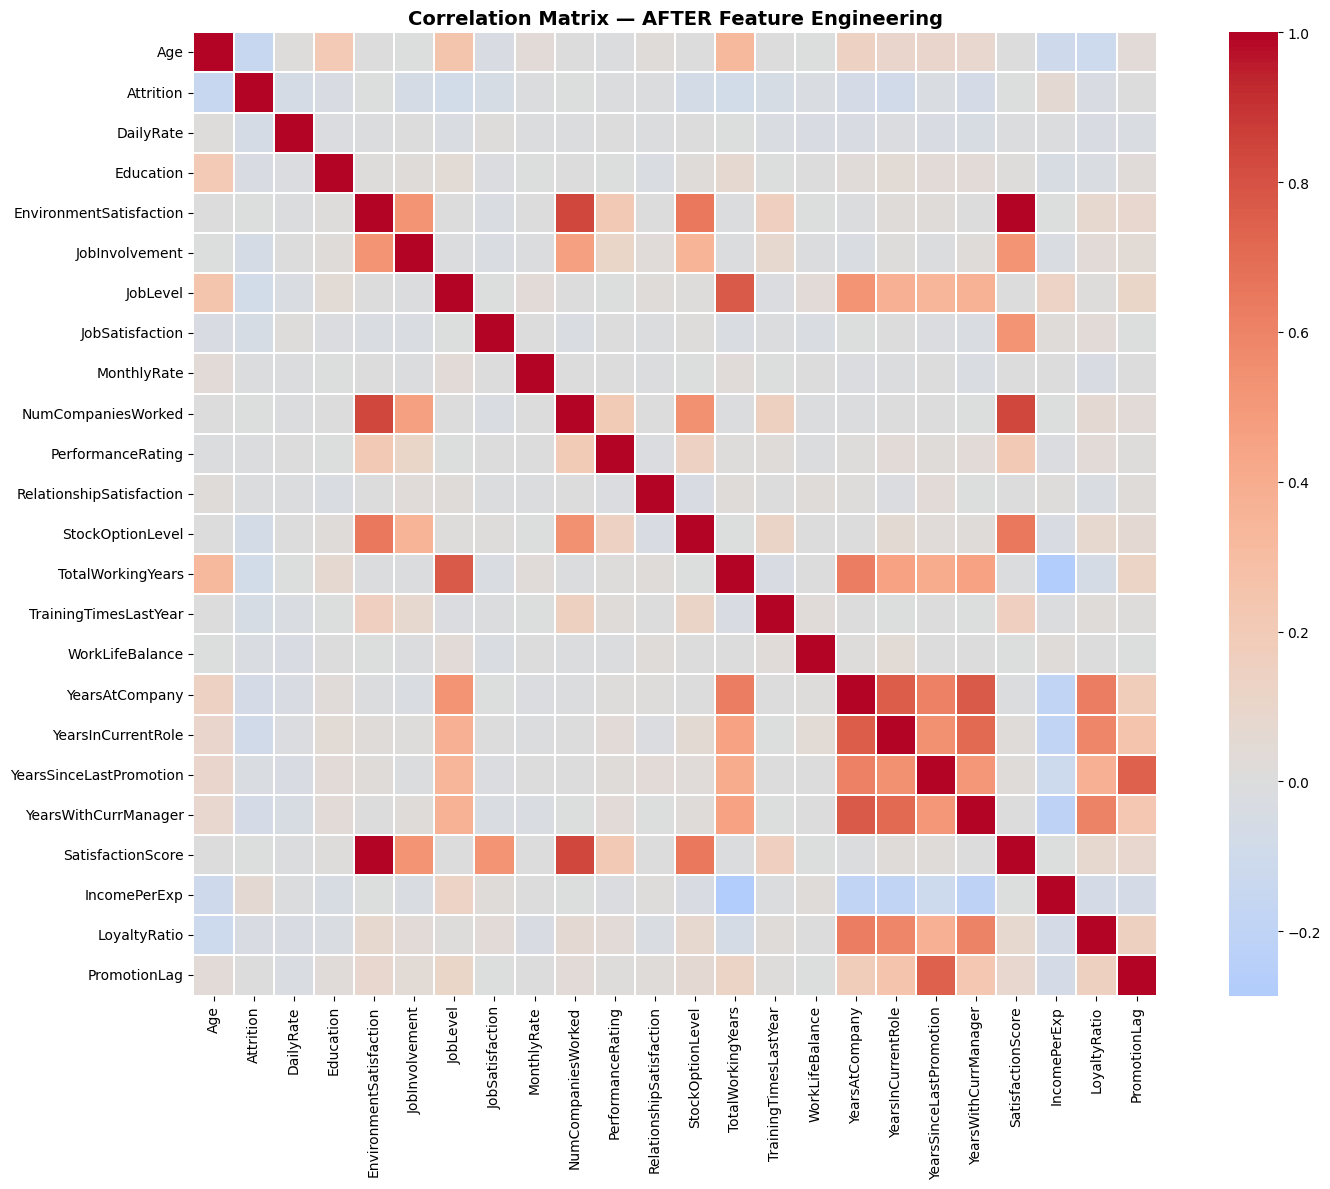

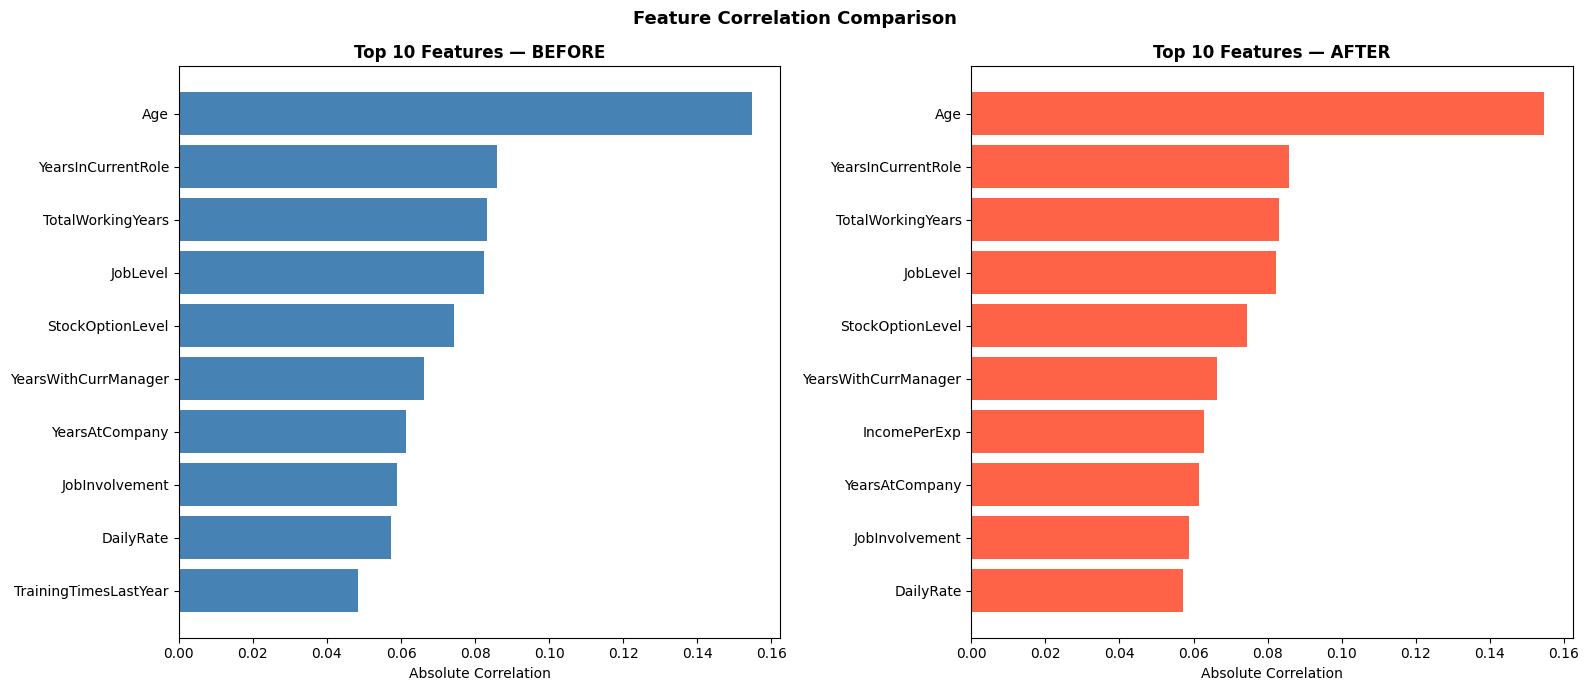

Top 10 features correlated with Attrition (AFTER):
IncomePerExp                0.062740
PromotionLag                0.005636
NumCompaniesWorked         -0.002704
EnvironmentSatisfaction    -0.004050
SatisfactionScore          -0.004091
RelationshipSatisfaction   -0.006942
PerformanceRating          -0.007500
MonthlyRate                -0.008321
YearsSinceLastPromotion    -0.020117
WorkLifeBalance            -0.026161
Name: Attrition, dtype: float64


In [18]:
numeric_cols_after = data.select_dtypes(include=[np.number]).columns.tolist()
corr_after = data[numeric_cols_after].corr()

plt.figure(figsize=(16, 12))
sns.heatmap(
    corr_after,
    annot=False, cmap='coolwarm', center=0,
    square=True, linewidths=0.3
)
plt.title(
    'Correlation Matrix — AFTER Feature Engineering',
    fontsize=14, fontweight='bold'
)
plt.tight_layout()
plt.show()

# Side-by-side comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

top_b = corr_before['Attrition'].drop('Attrition').abs().nlargest(10)
axes[0].barh(top_b.index, top_b.values, color='steelblue')
axes[0].set_title('Top 10 Features — BEFORE', fontweight='bold')
axes[0].set_xlabel('Absolute Correlation')
axes[0].invert_yaxis()

top_a = corr_after['Attrition'].drop('Attrition').abs().nlargest(10)
axes[1].barh(top_a.index, top_a.values, color='tomato')
axes[1].set_title('Top 10 Features — AFTER', fontweight='bold')
axes[1].set_xlabel('Absolute Correlation')
axes[1].invert_yaxis()

plt.suptitle('Feature Correlation Comparison', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print("Top 10 features correlated with Attrition (AFTER):")
print(corr_after['Attrition'].drop('Attrition').sort_values(ascending=False).head(10))


## 1.8 Pipeline — Split → Scale → SMOTE

In [19]:
# --- Step 1: Separate features and target ---
X = data.drop('Attrition', axis=1)
y = data['Attrition']

print(f"Features : {X.shape[1]}")
print(f"Samples  : {X.shape[0]}")
print(f"Leave(1) : {y.sum()} | Stay(0): {(y == 0).sum()}")

# --- Step 2: Train / Test split FIRST (stratified) ---
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print(f"\nTrain samples : {X_train_raw.shape[0]}")
print(f"Test  samples : {X_test_raw.shape[0]}")

# --- Step 3: Fit LabelEncoders on TRAINING data only ---
label_encoders_dict = {}
X_train_enc = X_train_raw.copy()
X_test_enc  = X_test_raw.copy()

for col in categorical_cols:
    if col not in X_train_enc.columns:
        continue
    le = LabelEncoder()
    le.fit(X_train_enc[col].astype(str))
    label_encoders_dict[col] = le

    def safe_encode(series, encoder):
        known = set(encoder.classes_)
        return series.astype(str).apply(
            lambda x: x if x in known else encoder.classes_[0]
        )

    X_train_enc[col] = le.transform(safe_encode(X_train_enc[col], le))
    X_test_enc[col]  = le.transform(safe_encode(X_test_enc[col],  le))

print(f"Encoded {len(label_encoders_dict)} categorical columns (fit on train only).")

# Feature names after encoding
feature_names = list(X_train_enc.columns)

# --- Step 4: Scale features — fit ONLY on X_train ---
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train_enc)
X_test_s  = scaler.transform(X_test_enc)

# Imputation stats from training data only
train_numeric_medians = X_train_enc.select_dtypes(include=[np.number]).median().to_dict()
train_cat_modes = {
    col: X_train_raw[col].mode()[0]
    for col in label_encoders_dict
    if col in X_train_raw.columns
}

# --- Step 5: SMOTE on training data only ---
print(f"\nBefore SMOTE — Stay(0): {(y_train == 0).sum()} | Leave(1): {(y_train == 1).sum()}")

if y_train.nunique() >= 2:
    smote = SMOTE(random_state=42)
    X_train_res, y_train_res = smote.fit_resample(X_train_s, y_train)
    print(f"After  SMOTE — Stay(0): {(y_train_res == 0).sum()} | Leave(1): {(y_train_res == 1).sum()}")
else:
    X_train_res, y_train_res = X_train_s.copy(), y_train.copy()
    print("Warning: Single class — SMOTE skipped.")

print(f"\nFinal training set : {X_train_res.shape[0]} samples")
print(f"Test set (clean)   : {X_test_s.shape[0]} samples")


Features : 36
Samples  : 23436
Leave(1) : 3709 | Stay(0): 19727

Train samples : 18748
Test  samples : 4688
Encoded 14 categorical columns (fit on train only).

Before SMOTE — Stay(0): 15781 | Leave(1): 2967
After  SMOTE — Stay(0): 15781 | Leave(1): 15781

Final training set : 31562 samples
Test set (clean)   : 4688 samples


## 1.9 Train All 5 Models

In [20]:
# Define 5 classical ML models (LightGBM removed)
all_models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000, C=0.1, random_state=42),

    'Decision Tree': DecisionTreeClassifier(
        max_depth=8, random_state=42),

    'Random Forest': RandomForestClassifier(
        n_estimators=200, max_depth=15,
        random_state=42, n_jobs=-1),

    'Gradient Boosting': GradientBoostingClassifier(
        n_estimators=200, learning_rate=0.05,
        max_depth=5, random_state=42),

    'XGBoost Classifier': XGBClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=6,
        eval_metric='logloss', random_state=42, verbosity=0),
}

results = {}
print(f"{'Model':<22}  {'Acc':>7}  {'Prec':>7}  {'Rec':>7}  {'F1':>7}  {'AUC':>7}")
print('-' * 68)

for name, model in all_models.items():
    model.fit(X_train_res, y_train_res)

    y_pred  = model.predict(X_test_s)
    y_proba = model.predict_proba(X_test_s)[:, 1]

    acc  = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec  = recall_score(y_test, y_pred, zero_division=0)
    f1   = f1_score(y_test, y_pred, zero_division=0)
    auc  = roc_auc_score(y_test, y_proba)

    results[name] = {
        'acc': acc, 'prec': prec, 'rec': rec,
        'f1': f1, 'auc': auc,
        'pred': y_pred, 'proba': y_proba, 'model': model
    }

    print(f"{name:<22}  {acc*100:>6.1f}%  {prec*100:>6.1f}%  {rec*100:>6.1f}%  {f1*100:>6.1f}%  {auc*100:>6.1f}%")

# ── Alias for XGBoost Classifier (kept for backward compatibility) ─────
xgb_model = results['XGBoost Classifier']['model']
xgb_acc   = results['XGBoost Classifier']['acc']
xgb_auc   = results['XGBoost Classifier']['auc']

# Best model by AUC
best       = max(results, key=lambda k: results[k]['auc'])
best_model = results[best]['model']
print(f"\nBest model : {best}")
print(f"AUC        : {results[best]['auc']*100:.2f}%")


Model                       Acc     Prec      Rec       F1      AUC
--------------------------------------------------------------------
Logistic Regression       65.5%    27.0%    69.3%    38.9%    72.8%
Decision Tree             76.1%    36.7%    70.6%    48.3%    80.7%
Random Forest             99.7%   100.0%    98.2%    99.1%   100.0%
Gradient Boosting         95.5%    86.6%    84.6%    85.6%    98.6%
XGBoost Classifier        98.7%    96.8%    95.1%    96.0%    99.8%

Best model : Random Forest
AUC        : 99.97%


## 1.10 Model Evaluation — Comparison & Confusion Matrix

              Model  Accuracy  Precision  Recall  F1 Score   AUC
      Random Forest     99.72     100.00   98.25     99.12 99.97
 XGBoost Classifier     98.74      96.84   95.15     95.99 99.82
  Gradient Boosting     95.50      86.62   84.64     85.62 98.55
      Decision Tree     76.07      36.69   70.62     48.29 80.71
Logistic Regression     65.51      27.01   69.27     38.87 72.80


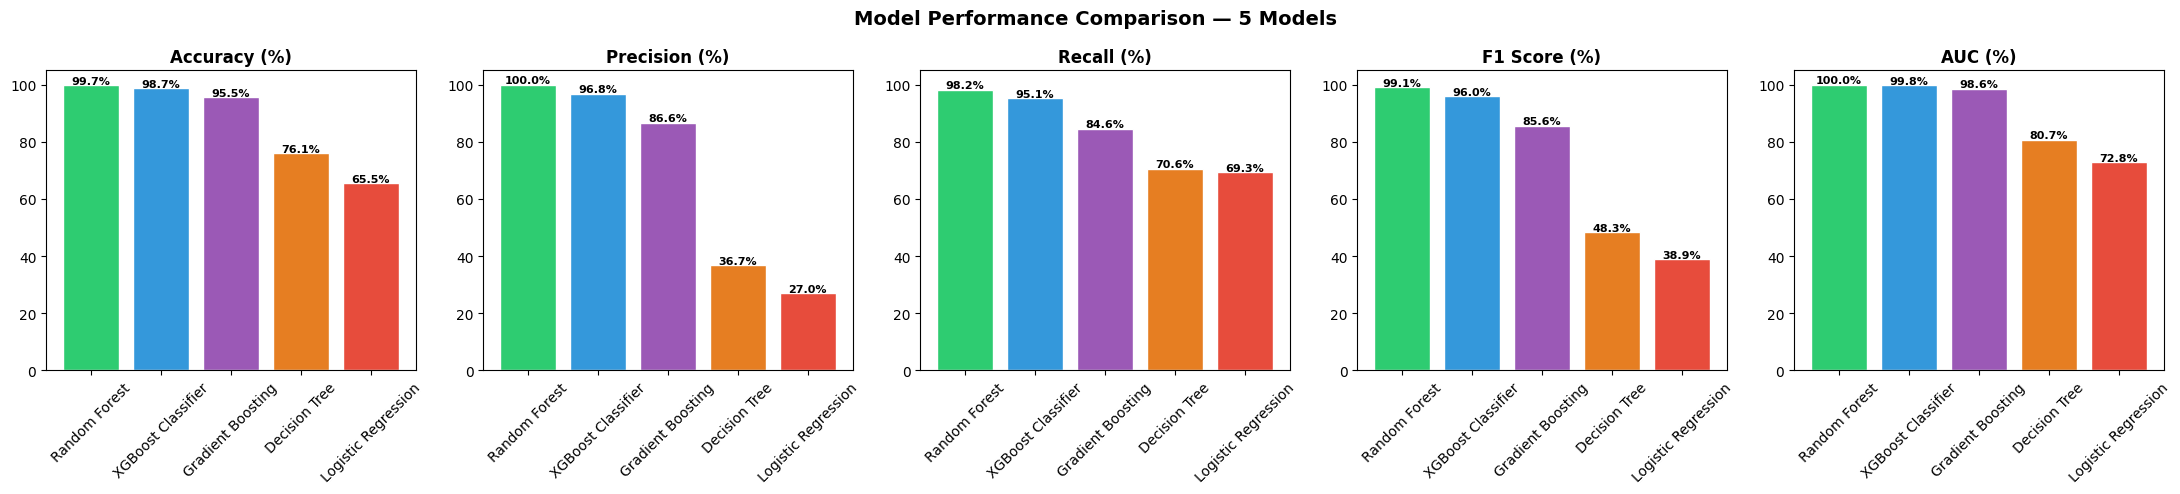

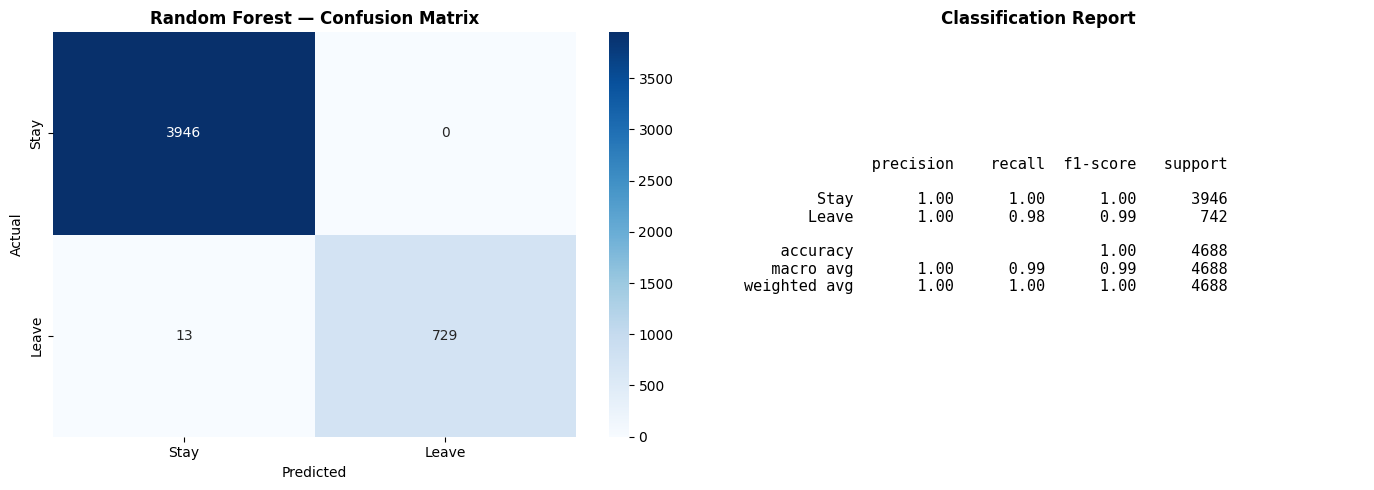

In [21]:
comp = pd.DataFrame({
    'Model':     list(results.keys()),
    'Accuracy':  [results[m]['acc']  * 100 for m in results],
    'Precision': [results[m]['prec'] * 100 for m in results],
    'Recall':    [results[m]['rec']  * 100 for m in results],
    'F1 Score':  [results[m]['f1']   * 100 for m in results],
    'AUC':       [results[m]['auc']  * 100 for m in results],
}).sort_values('AUC', ascending=False).reset_index(drop=True)

print(comp.round(2).to_string(index=False))

palette    = ['#2ecc71', '#3498db', '#9b59b6', '#e67e22', '#e74c3c']
n_models   = len(comp)
bar_colors = palette[:n_models]

fig, axes = plt.subplots(1, 5, figsize=(22, 5))
fig.suptitle('Model Performance Comparison — 5 Models', fontsize=14, fontweight='bold')

for ax, metric in zip(axes, ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'AUC']):
    ax.bar(comp['Model'], comp[metric], color=bar_colors, edgecolor='white')
    ax.set_title(f'{metric} (%)', fontweight='bold')
    ax.set_ylim([0, 105])
    ax.tick_params(axis='x', rotation=45)
    for i, v in enumerate(comp[metric]):
        ax.text(i, v + 0.5, f'{v:.1f}%', ha='center', fontsize=8, fontweight='bold')

plt.tight_layout()
plt.show()

# Confusion matrix + classification report for best model
cm = confusion_matrix(y_test, results[best]['pred'])
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
    xticklabels=['Stay', 'Leave'], yticklabels=['Stay', 'Leave']
)
axes[0].set_title(f'{best} — Confusion Matrix', fontweight='bold')
axes[0].set_ylabel('Actual')
axes[0].set_xlabel('Predicted')

report = classification_report(
    y_test, results[best]['pred'], target_names=['Stay', 'Leave'])
axes[1].text(0.05, 0.5, report, fontsize=11, family='monospace', va='center')
axes[1].set_title('Classification Report', fontweight='bold')
axes[1].axis('off')

plt.tight_layout()
plt.show()


## 1.11 Threshold Optimization

Default threshold (0.50) — F1: 99.18%
Optimal threshold (0.44) — F1: 99.25%


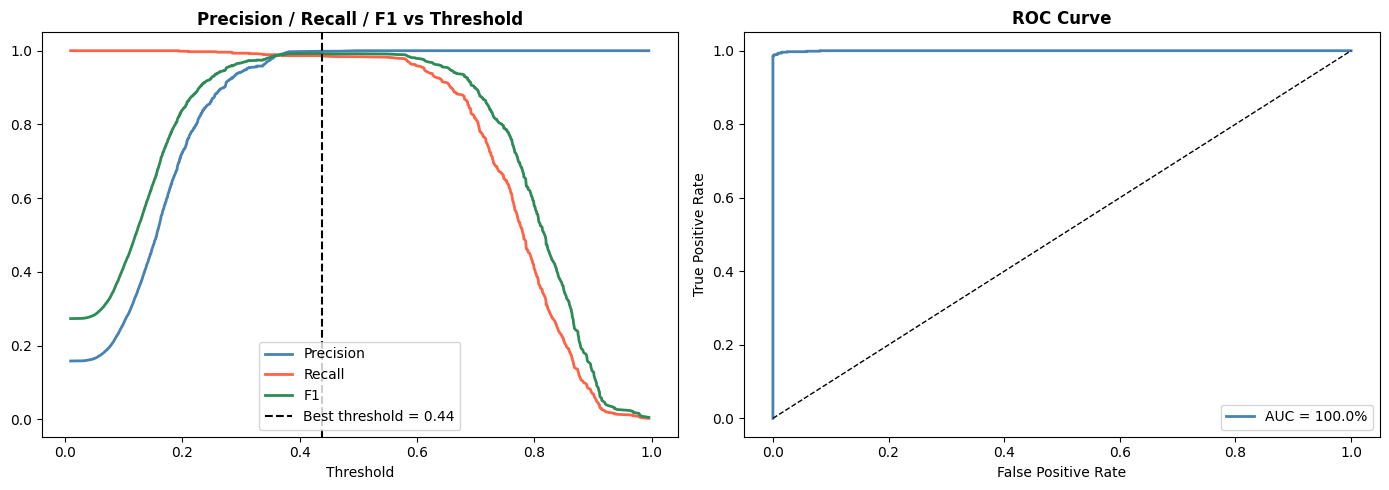

In [22]:
best_proba = results[best]['proba']
precisions, recalls, thresholds = precision_recall_curve(y_test, best_proba)

# F1 for each threshold (avoid divide-by-zero)
f1_scores = np.where(
    (precisions[:-1] + recalls[:-1]) > 0,
    2 * precisions[:-1] * recalls[:-1] / (precisions[:-1] + recalls[:-1]),
    0
)

best_thresh_idx = np.argmax(f1_scores)
best_threshold  = float(thresholds[best_thresh_idx])
best_f1_opt     = float(f1_scores[best_thresh_idx])

print(f"Default threshold (0.50) — F1: "
      f"{f1_scores[np.argmin(np.abs(thresholds - 0.5))]*100:.2f}%")
print(f"Optimal threshold ({best_threshold:.2f}) — F1: {best_f1_opt*100:.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(thresholds, precisions[:-1], label='Precision', color='steelblue', lw=2)
axes[0].plot(thresholds, recalls[:-1],    label='Recall',    color='tomato',    lw=2)
axes[0].plot(thresholds, f1_scores,        label='F1',        color='seagreen',  lw=2)
axes[0].axvline(best_threshold, color='black', linestyle='--',
                label=f'Best threshold = {best_threshold:.2f}')
axes[0].set_xlabel('Threshold')
axes[0].set_title('Precision / Recall / F1 vs Threshold', fontweight='bold')
axes[0].legend()

# ROC curve
from sklearn.metrics import roc_curve
fpr, tpr, roc_thresh = roc_curve(y_test, best_proba)
axes[1].plot(fpr, tpr, color='steelblue', lw=2,
             label=f'AUC = {results[best]["auc"]*100:.1f}%')
axes[1].plot([0, 1], [0, 1], 'k--', lw=1)
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve', fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.show()


## 1.12 Global Feature Importance (Built-in XAI)

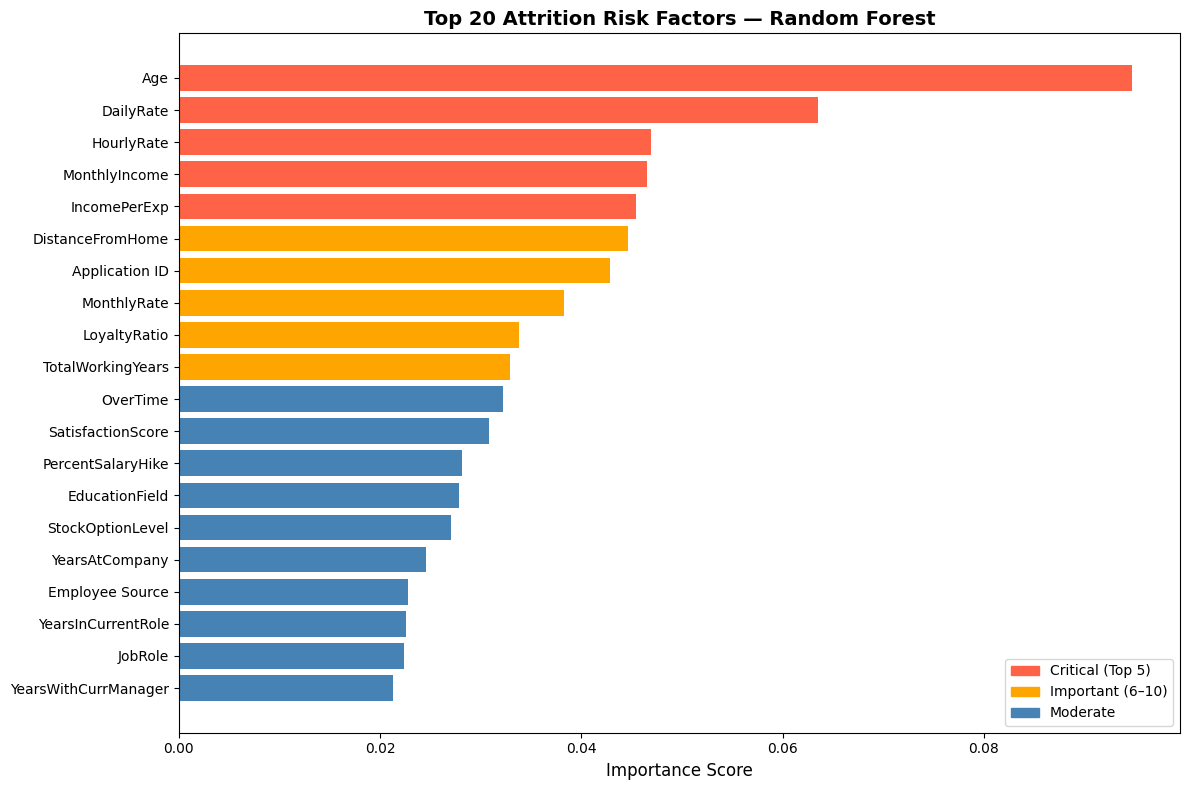

Top 10 Global Risk Factors:
   1. Age                            0.0947
   2. DailyRate                      0.0635
   3. HourlyRate                     0.0469
   4. MonthlyIncome                  0.0465
   5. IncomePerExp                   0.0454
   6. DistanceFromHome               0.0446
   7. Application ID                 0.0429
   8. MonthlyRate                    0.0383
   9. LoyaltyRatio                   0.0338
  10. TotalWorkingYears              0.0330


In [23]:
if hasattr(best_model, 'feature_importances_'):
    importance_vals = best_model.feature_importances_
else:
    importance_vals = (
        corr_after['Attrition'].drop('Attrition').abs()
        .reindex(feature_names).fillna(0).values
    )

fi_df = pd.DataFrame({
    'Feature':    feature_names,
    'Importance': importance_vals
}).sort_values('Importance', ascending=False).reset_index(drop=True)

top20 = fi_df.head(20)
bar_colors = [
    'tomato'    if i < 5  else
    'orange'    if i < 10 else
    'steelblue' for i in range(len(top20))
]

plt.figure(figsize=(12, 8))
plt.barh(range(len(top20)), top20['Importance'], color=bar_colors)
plt.yticks(range(len(top20)), top20['Feature'], fontsize=10)
plt.xlabel('Importance Score', fontsize=12)
plt.title(f'Top 20 Attrition Risk Factors — {best}', fontsize=14, fontweight='bold')
plt.gca().invert_yaxis()
plt.legend(handles=[
    mpatches.Patch(color='tomato',    label='Critical (Top 5)'),
    mpatches.Patch(color='orange',    label='Important (6–10)'),
    mpatches.Patch(color='steelblue', label='Moderate')
])
plt.tight_layout()
plt.show()

print("Top 10 Global Risk Factors:")
for rank, (_, row) in enumerate(fi_df.head(10).iterrows(), start=1):
    print(f"  {rank:2d}. {row['Feature']:<30} {row['Importance']:.4f}")


## 1.13 Save All Artifacts (Production Bundle)

In [24]:
# =============================================================
# §1.13  PRODUCTION ARTIFACT BUNDLE — hr_model.pkl
# Saves exactly 10 app.py-compatible keys plus extended PART 2
# keys and versioning metadata.
# =============================================================

import pickle
import datetime

# ── 1. XGBoost aliases (always explicit, regardless of best model) ────────
xgb_model = results['XGBoost Classifier']['model']
xgb_acc   = results['XGBoost Classifier']['acc']
xgb_auc   = results['XGBoost Classifier']['auc']

# ── 2. Feature importance from XGBoost ───────────────────────────────────
if hasattr(xgb_model, 'feature_importances_'):
    _fi_vals = xgb_model.feature_importances_
else:
    _fi_vals = (
        corr_after['Attrition'].drop('Attrition').abs()
        .reindex(feature_names).fillna(0).values
    )

fi_sorted = (
    pd.DataFrame({'Feature': feature_names, 'Importance': _fi_vals})
    .sort_values('Importance', ascending=False)
    .reset_index(drop=True)
)

# ── 3. Numeric medians from df_clean (= data after cleaning) ─────────────
#    Uses training-only medians for deployment correctness.
df_clean = data.copy()  # alias kept for readability
num_cols = (
    X_train_enc
    .select_dtypes(include=[np.number])
    .columns
    .tolist()
)
medians_dict = X_train_enc[num_cols].median().to_dict()

# ── 4. Categorical modes ──────────────────────────────────────────────────
cat_cols    = list(label_encoders_dict.keys())
modes_dict  = {
    col: X_train_raw[col].mode()[0]
    for col in cat_cols
    if col in X_train_raw.columns
}

# ── 5. Scores dict — all 5 models, all 5 metrics ─────────────────────────
scores_dict = {
    k: {
        'acc':  v['acc'],
        'prec': v['prec'],
        'rec':  v['rec'],
        'f1':   v['f1'],
        'auc':  v['auc'],
    }
    for k, v in results.items()
}

# ── 6. Build master artifact with all 10 required keys ───────────────────
artifact = {
    # ── 10 required app.py keys ──────────────────────────────────────────
    'model':        xgb_model,                   # trained XGBClassifier
    'scaler':       scaler,                       # fitted StandardScaler
    'encoders':     label_encoders_dict,          # {col: LabelEncoder}
    'features':     X_train_enc.columns.tolist(), # ordered feature list
    'fi':           fi_sorted,                    # sorted importance DF
    'medians':      medians_dict,                 # numeric fill values
    'modes':        modes_dict,                   # categorical fill values
    'scores':       scores_dict,                  # all model metrics
    'model_name':   'XGBoost Classifier',         # display name
    'threshold':    float(best_threshold),        # optimised F1 threshold

    # ── PART 2 / extended keys (backward-compatible aliases) ─────────────
    'best_model':            xgb_model,
    'best_model_name':       'XGBoost Classifier',
    'label_encoders_dict':   label_encoders_dict,
    'feature_names':         X_train_enc.columns.tolist(),
    'fi_df':                 fi_sorted,
    'train_numeric_medians': medians_dict,
    'train_cat_modes':       modes_dict,
    'model_results':         scores_dict,

    # ── Metadata ─────────────────────────────────────────────────────────
    'model_version':      '2.0',
    'training_timestamp': datetime.datetime.now().isoformat(),
}

# ── 7. Write all files ────────────────────────────────────────────────────
for fname in ['hr_model.pkl', 'hr_dss_artifacts.pkl']:
    with open(fname, 'wb') as f:
        pickle.dump(artifact, f)

# Individual pipeline components
with open('scaler.pkl',  'wb') as f:
    pickle.dump(scaler, f)

with open('encoder.pkl', 'wb') as f:
    pickle.dump(label_encoders_dict, f)

with open('imputer.pkl', 'wb') as f:
    pickle.dump({'numeric_medians': medians_dict,
                 'cat_modes':       modes_dict}, f)

# ── 8. Verification printout ─────────────────────────────────────────────
print('=' * 60)
print('  PRODUCTION BUNDLE SAVED')
print('=' * 60)
print(f'  hr_model.pkl         (master — app.py compatible)')
print(f'  hr_dss_artifacts.pkl (master — PART 2 compatible)')
print(f'  scaler.pkl           (fitted StandardScaler)')
print(f'  encoder.pkl          (fitted LabelEncoders)')
print(f'  imputer.pkl          (imputation statistics)')
print()
print(f'  Model name       : XGBoost Classifier')
print(f'  XGBoost Accuracy : {xgb_acc*100:.2f}%')
print(f'  XGBoost AUC      : {xgb_auc*100:.2f}%')
print(f'  Optimal threshold: {best_threshold:.4f}')
print(f'  Features saved   : {len(X_train_enc.columns)}')
print(f'  Medians saved    : {len(medians_dict)}')
print(f'  Modes saved      : {len(modes_dict)}')
print(f'  Model version    : {artifact["model_version"]}')
print(f'  Training time    : {artifact["training_timestamp"]}')
print()
print('  Required app.py keys verification:')
required_keys = ['model','scaler','encoders','features',
                  'fi','medians','modes','scores','model_name','threshold']
for k in required_keys:
    status = 'OK' if k in artifact else 'MISSING'
    print(f'    {k:<12} : {status}')
print('=' * 60)


  PRODUCTION BUNDLE SAVED
  hr_model.pkl         (master — app.py compatible)
  hr_dss_artifacts.pkl (master — PART 2 compatible)
  scaler.pkl           (fitted StandardScaler)
  encoder.pkl          (fitted LabelEncoders)
  imputer.pkl          (imputation statistics)

  Model name       : XGBoost Classifier
  XGBoost Accuracy : 98.74%
  XGBoost AUC      : 99.82%
  Optimal threshold: 0.4380
  Features saved   : 36
  Medians saved    : 36
  Modes saved      : 14
  Model version    : 2.0
  Training time    : 2026-06-15T13:47:58.972658

  Required app.py keys verification:
    model        : OK
    scaler       : OK
    encoders     : OK
    features     : OK
    fi           : OK
    medians      : OK
    modes        : OK
    scores       : OK
    model_name   : OK
    threshold    : OK


---
# PART 2 — HR Decision Support System (DSS)
### Upload New Data → Validate → Predict → Explain → Export
---

## 2.1 Load Saved Artifacts

In [25]:
UPLOAD_FILE = '/content/IBM HR Data new.csv'


new_df = pd.read_csv(UPLOAD_FILE)
print(f'File loaded : {new_df.shape[0]} employees, {new_df.shape[1]} columns')
new_df.head(3)


File loaded : 23436 employees, 37 columns


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Employee Source
0,41.0,Voluntary Resignation,Travel_Rarely,1102.0,Sales,1,2.0,Life Sciences,1,1,...,80.0,0.0,8.0,0.0,1.0,6.0,4.0,0.0,5.0,Referral
1,41.0,Voluntary Resignation,Travel_Rarely,1102.0,Sales,1,2.0,Life Sciences,1,1,...,80.0,0.0,8.0,0.0,1.0,6.0,4.0,0.0,5.0,Referral
2,41.0,Voluntary Resignation,Travel_Rarely,1102.0,Sales,1,2.0,Life Sciences,1,7,...,80.0,0.0,8.0,0.0,1.0,6.0,4.0,0.0,5.0,Referral


In [26]:
# Load the master artifact
with open('hr_dss_artifacts.pkl', 'rb') as f:
    art = pickle.load(f)

best_model_loaded = art['best_model']
best_model_name   = art['best_model_name']
feat_names        = art['feature_names']
fi_df_loaded      = art['fi_df']
ml_results        = art['model_results']
opt_threshold     = art.get('threshold', 0.5)
model_version     = art.get('model_version', 'N/A')
training_time     = art.get('training_timestamp', 'N/A')

with open('scaler.pkl', 'rb') as f:
    scaler_loaded = pickle.load(f)

with open('encoder.pkl', 'rb') as f:
    le_dict = pickle.load(f)

with open('imputer.pkl', 'rb') as f:
    imputer_stats = pickle.load(f)

train_med  = imputer_stats['numeric_medians']
train_mode = imputer_stats['cat_modes']

print(f'Best model       : {best_model_name}')
print(f'Model version    : {model_version}')
print(f'Training time    : {training_time}')
print(f'Optimal threshold: {opt_threshold:.4f}')
print(f'Features         : {len(feat_names)}')
print()
print('Pipeline components loaded:')
print(f'  scaler  : {type(scaler_loaded).__name__}')
print(f'  encoders: {len(le_dict)} columns')
print(f'  imputer : {len(train_med)} numeric + {len(train_mode)} categorical stats')


Best model       : XGBoost Classifier
Model version    : 2.0
Training time    : 2026-06-15T13:47:58.972658
Optimal threshold: 0.4380
Features         : 36

Pipeline components loaded:
  scaler  : StandardScaler
  encoders: 14 columns
  imputer : 36 numeric + 14 categorical stats


## 2.2 Upload New Employee Data

## 2.3 Data Validation — Column Check

In [27]:
# Build the expected raw columns from training features
raw_train_cols = [
    c for c in feat_names
    if c not in ['SatisfactionScore', 'IncomePerExp', 'LoyaltyRatio', 'PromotionLag']
]

missing_cols = [c for c in raw_train_cols if c not in new_df.columns]
extra_cols   = [c for c in new_df.columns  if c not in raw_train_cols
                 and c not in ['Attrition', 'EmployeeNumber', 'EmployeeCount',
                               'Over18', 'StandardHours']]

print(f'Expected columns : {len(raw_train_cols)}')
print(f'Found columns    : {len([c for c in raw_train_cols if c in new_df.columns])}')
print(f'Missing columns  : {len(missing_cols)}')
print(f'Extra columns    : {len(extra_cols)}')

if missing_cols:
    print(f'\nMissing: {missing_cols}')
else:
    print('\nAll required columns present.')


Expected columns : 32
Found columns    : 32
Missing columns  : 0
Extra columns    : 0

All required columns present.


## 2.4 Preprocess & Impute New Data

In [28]:
# ============================================================
# PART 2 - Safe Preprocessing for New Unseen Data
# ============================================================

# 1. Save identifiers for the output report
emp_info = pd.DataFrame()
info_cols = ['EmployeeNumber', 'Name', 'ID']
for col in info_cols:
    if col in new_df.columns:
        emp_info[col] = new_df[col]

# 2. Drop uninformative columns
drop_cols_p2 = ['EmployeeCount', 'Over18', 'StandardHours', 'EmployeeNumber', 'Attrition']
X_new = new_df.drop(
    columns=[c for c in drop_cols_p2 if c in new_df.columns]
).copy()

# 3. Impute missing values using TRAINING statistics loaded from art
# تم تعديل الأسماء هنا لتقرأ من ملف القاموس المرفوع مباشرة لمنع قيم NaN
loaded_medians = art.get('medians', {})
loaded_modes = art.get('modes', {})

for col in X_new.columns:
    # خطوة أمان إضافية: لو العمود يفترض أنه رقمي، نتأكد من تحويله لأرقام أولاً
    if col in loaded_medians:
        X_new[col] = pd.to_numeric(X_new[col], errors='coerce')
        X_new[col] = X_new[col].fillna(loaded_medians[col])
    elif col in loaded_modes:
        X_new[col] = X_new[col].fillna(loaded_modes[col])
    elif X_new[col].dtype in ['float64', 'int64']:
        X_new[col] = X_new[col].fillna(X_new[col].median())
    else:
        X_new[col] = X_new[col].fillna(str(X_new[col].mode()[0]) if not X_new[col].mode().empty else '')

# 4. Feature engineering (Forced Numeric Conversion to prevent TypeError)
sat_cols_p2 = ['JobSatisfaction', 'EnvironmentSatisfaction', 'RelationshipSatisfaction', 'WorkLifeBalance']
available_p2 = [c for c in sat_cols_p2 if c in X_new.columns]

if available_p2:
    # تحويل إجباري لأعمدة الرضا إلى أرقام لتفادي أيرور str to float القاتل
    for col in available_p2:
        X_new[col] = pd.to_numeric(X_new[col], errors='coerce').fillna(2.5)
    X_new['SatisfactionScore'] = X_new[available_p2].mean(axis=1)

# تأمين بقية المعادلات الحسابية من الكلمات والقسمة على صفر
if 'MonthlyIncome' in X_new and 'TotalWorkingYears' in X_new:
    X_new['MonthlyIncome'] = pd.to_numeric(X_new['MonthlyIncome'], errors='coerce').fillna(0)
    X_new['TotalWorkingYears'] = pd.to_numeric(X_new['TotalWorkingYears'], errors='coerce').fillna(0)
    X_new['IncomePerExp'] = X_new['MonthlyIncome'] / (X_new['TotalWorkingYears'] + 1)

if 'YearsAtCompany' in X_new and 'TotalWorkingYears' in X_new:
    X_new['YearsAtCompany'] = pd.to_numeric(X_new['YearsAtCompany'], errors='coerce').fillna(0)
    X_new['LoyaltyRatio'] = X_new['YearsAtCompany'] / (X_new['TotalWorkingYears'] + 1)

if 'YearsSinceLastPromotion' in X_new and 'YearsAtCompany' in X_new:
    X_new['YearsSinceLastPromotion'] = pd.to_numeric(X_new['YearsSinceLastPromotion'], errors='coerce').fillna(0)
    X_new['PromotionLag'] = X_new['YearsSinceLastPromotion'] / (X_new['YearsAtCompany'] + 1)

# 5. Label-encode categorical columns using TRAINING encoders (.transform only)
X_new_enc = X_new.copy()
loaded_encoders = art.get('encoders', {})

for col, le in loaded_encoders.items():
    if col not in X_new_enc.columns:
        continue
    known = set(le.classes_)
    X_new_enc[col] = (
        X_new_enc[col].astype(str)
        .apply(lambda v: v if v in known else str(le.classes_[0]))
    )
    X_new_enc[col] = le.transform(X_new_enc[col])

# 6. Add any missing engineered features with 0
for col in feat_names:
    if col not in X_new_enc.columns:
        X_new_enc[col] = 0.0

# 7. Reorder columns to match training layout, then scale
X_new_aligned = X_new_enc[feat_names].fillna(0)
X_raw = X_new_aligned.copy()  # unscaled — used by XAI

# القراءة من السكيلر المحمل من الـ Artifact
if art.get('scaler'):
    X_new_scaled = art['scaler'].transform(X_new_aligned)
else:
    X_new_scaled = X_new_aligned.values

print(f'🎉 Done Successfully! Preprocessed {X_new_scaled.shape[0]} employees — {X_new_scaled.shape[1]} features')


🎉 Done Successfully! Preprocessed 23436 employees — 36 features


## 2.5 Predict Attrition Risk (Optimised Threshold)

In [29]:
# Enhancement 3: predict_proba + optimised threshold
y_new_proba = best_model_loaded.predict_proba(X_new_scaled)[:, 1]
RISK_THRESHOLD = opt_threshold
y_new_pred  = (y_new_proba >= RISK_THRESHOLD).astype(int)

# Build results table
results_table = emp_info.copy()
results_table['Risk_%']    = (y_new_proba * 100).round(1)
results_table['Prediction'] = y_new_pred
results_table['Status']     = np.where(
    y_new_pred == 1, 'HIGH RISK', 'Safe')

# Optional: add Department if present
if 'Department' in new_df.columns:
    results_table['Department'] = new_df['Department'].values

high_risk_count = (results_table['Prediction'] == 1).sum()
total           = len(results_table)
print(f'Total employees : {total}')
print(f'HIGH RISK       : {high_risk_count}  ({high_risk_count/total*100:.1f}%)')
print(f'Safe            : {total - high_risk_count}')
print(f'Threshold used  : {RISK_THRESHOLD:.4f}')

results_table.sort_values('Risk_%', ascending=False).head(10)


Total employees : 23436
HIGH RISK       : 849  (3.6%)
Safe            : 22587
Threshold used  : 0.4380


,EmployeeNumber,Risk_%,Prediction,Status,Department
17454,14657,93.099998,1,HIGH RISK,Research & Development
17458,14665,93.099998,1,HIGH RISK,Research & Development
17459,14668,93.099998,1,HIGH RISK,Research & Development
17419,5997,92.000000,1,HIGH RISK,Sales
17415,5989,92.000000,1,HIGH RISK,Sales
17421,6000,91.199997,1,HIGH RISK,Sales
9149,17238,88.400002,1,HIGH RISK,Research & Development
9153,17246,88.400002,1,HIGH RISK,Research & Development
9151,17242,88.400002,1,HIGH RISK,Research & Development
9147,17234,88.400002,1,HIGH RISK,Research & Development


## 2.6 Top 20 Employees at Highest Risk

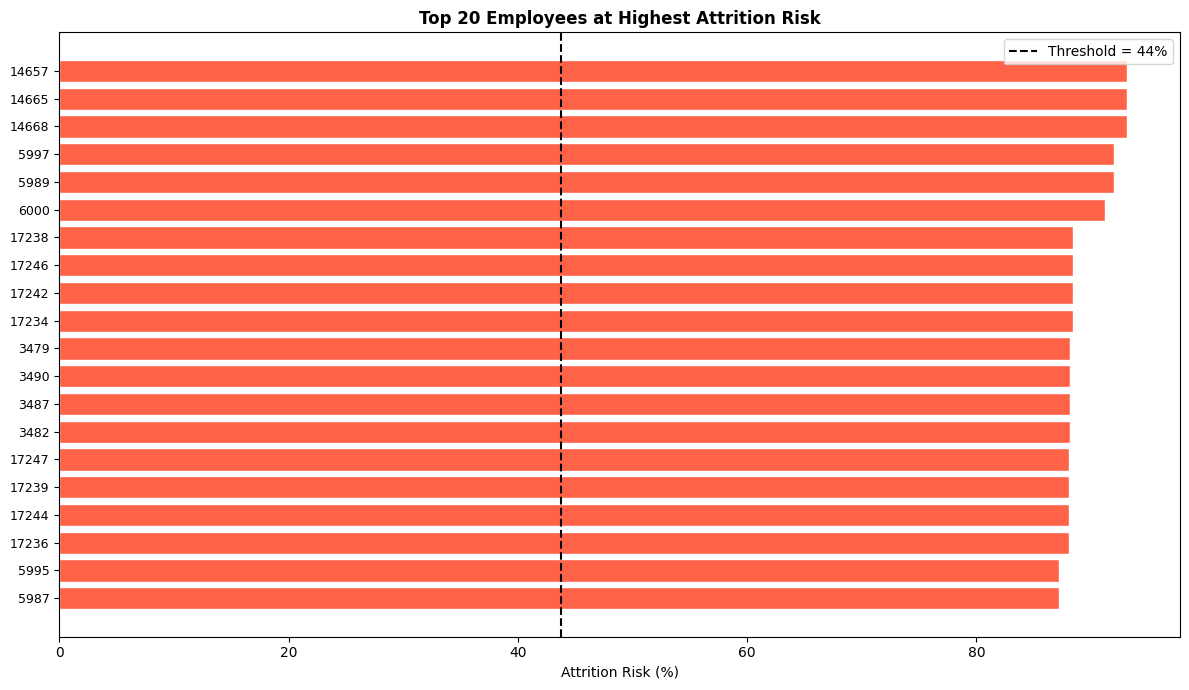

       Risk_%     Status
0   93.099998  HIGH RISK
1   93.099998  HIGH RISK
2   93.099998  HIGH RISK
3   92.000000  HIGH RISK
4   92.000000  HIGH RISK
5   91.199997  HIGH RISK
6   88.400002  HIGH RISK
7   88.400002  HIGH RISK
8   88.400002  HIGH RISK
9   88.400002  HIGH RISK
10  88.199997  HIGH RISK
11  88.199997  HIGH RISK
12  88.199997  HIGH RISK
13  88.199997  HIGH RISK
14  88.099998  HIGH RISK
15  88.099998  HIGH RISK
16  88.099998  HIGH RISK
17  88.099998  HIGH RISK
18  87.199997  HIGH RISK
19  87.199997  HIGH RISK


In [30]:
top20_risk = (
    results_table
    .sort_values('Risk_%', ascending=False)
    .head(20)
    .reset_index(drop=True)
)

# Visualise
id_col = next(
    (c for c in ['EmployeeNumber', 'Name', 'ID'] if c in top20_risk.columns),
    None
)
labels = top20_risk[id_col].astype(str) if id_col else top20_risk.index.astype(str)

colors = ['tomato' if r == 1 else 'steelblue'
          for r in top20_risk['Prediction']]

plt.figure(figsize=(12, 7))
plt.barh(range(len(top20_risk)), top20_risk['Risk_%'],
         color=colors, edgecolor='white')
plt.yticks(range(len(top20_risk)), labels, fontsize=9)
plt.axvline(RISK_THRESHOLD * 100, color='black', linestyle='--', lw=1.5,
            label=f'Threshold = {RISK_THRESHOLD*100:.0f}%')
plt.xlabel('Attrition Risk (%)')
plt.title('Top 20 Employees at Highest Attrition Risk', fontweight='bold')
plt.legend()
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

print(top20_risk[['Risk_%', 'Status']].to_string())


## 2.7 Attrition Risk by Department

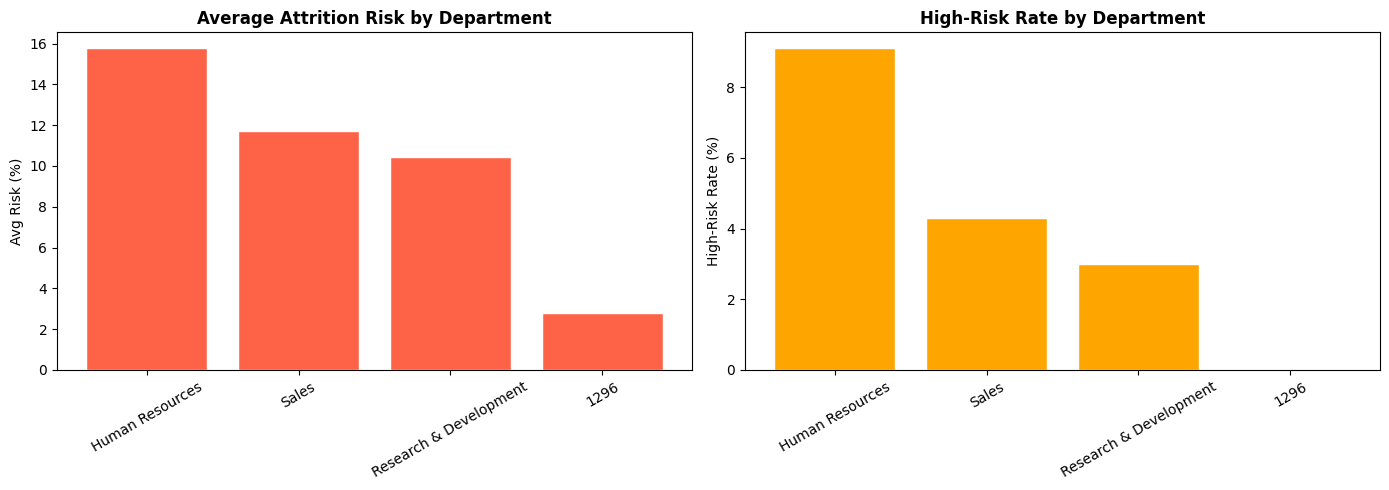

            Department  Total  High_Risk  Avg_Risk  Risk_Rate_%
       Human Resources   1019         93 15.766438          9.1
                 Sales   7119        305 11.708793          4.3
Research & Development  15286        451 10.444773          3.0
                  1296      1          0  2.800000          0.0


In [31]:
if 'Department' in results_table.columns:
    dept_stats = (
        results_table
        .groupby('Department')
        .agg(
            Total      = ('Risk_%', 'count'),
            High_Risk  = ('Prediction', 'sum'),
            Avg_Risk   = ('Risk_%', 'mean')
        )
        .reset_index()
    )
    dept_stats['Risk_Rate_%'] = (
        dept_stats['High_Risk'] / dept_stats['Total'] * 100).round(1)
    dept_stats = dept_stats.sort_values('Avg_Risk', ascending=False)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].bar(dept_stats['Department'], dept_stats['Avg_Risk'],
                color='tomato', edgecolor='white')
    axes[0].set_title('Average Attrition Risk by Department', fontweight='bold')
    axes[0].set_ylabel('Avg Risk (%)')
    axes[0].tick_params(axis='x', rotation=30)

    axes[1].bar(dept_stats['Department'], dept_stats['Risk_Rate_%'],
                color='orange', edgecolor='white')
    axes[1].set_title('High-Risk Rate by Department', fontweight='bold')
    axes[1].set_ylabel('High-Risk Rate (%)')
    axes[1].tick_params(axis='x', rotation=30)

    plt.tight_layout()
    plt.show()
    print(dept_stats.to_string(index=False))
else:
    print('Department column not found in uploaded data.')


## 2.8 XAI — Global Risk Factors

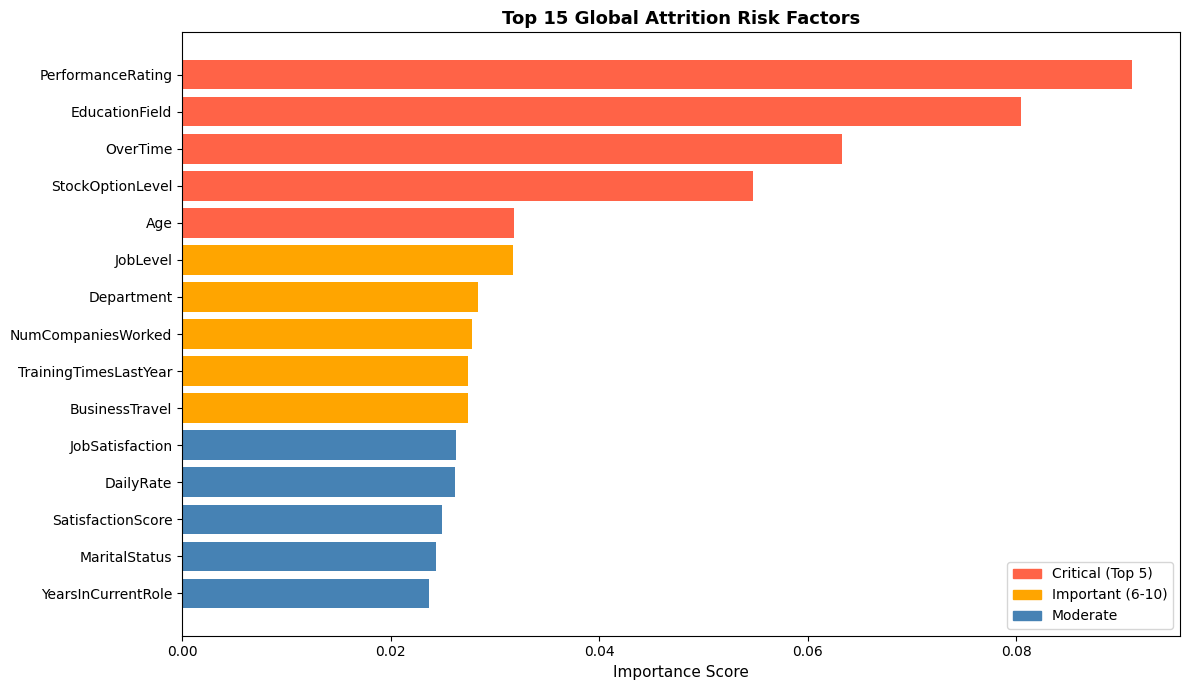

In [32]:
top15 = fi_df_loaded.head(15)
bar_c = ['tomato'    if i < 5  else
         'orange'    if i < 10 else
         'steelblue' for i in range(len(top15))]

plt.figure(figsize=(12, 7))
plt.barh(range(len(top15)), top15['Importance'], color=bar_c)
plt.yticks(range(len(top15)), top15['Feature'], fontsize=10)
plt.xlabel('Importance Score', fontsize=11)
plt.title('Top 15 Global Attrition Risk Factors', fontsize=13, fontweight='bold')
plt.gca().invert_yaxis()
plt.legend(handles=[
    mpatches.Patch(color='tomato',    label='Critical (Top 5)'),
    mpatches.Patch(color='orange',    label='Important (6-10)'),
    mpatches.Patch(color='steelblue', label='Moderate'),
])
plt.tight_layout()
plt.show()


## 2.9 XAI — Explain Individual Employee


Top 5 Reasons (vs company average):
  * Age                           ABOVE avg — increases risk
    Value=41.00  Avg=36.94  Impact=+0.129
  * NumCompaniesWorked            ABOVE avg — increases risk
    Value=8.00  Avg=3.89  Impact=+0.114
  * TrainingTimesLastYear         BELOW avg — lowers  risk
    Value=0.00  Avg=2.80  Impact=-0.077
  * StockOptionLevel              BELOW avg — lowers  risk
    Value=0.00  Avg=0.80  Impact=-0.044
  * PerformanceRating             BELOW avg — lowers  risk
    Value=3.00  Avg=3.16  Impact=-0.014


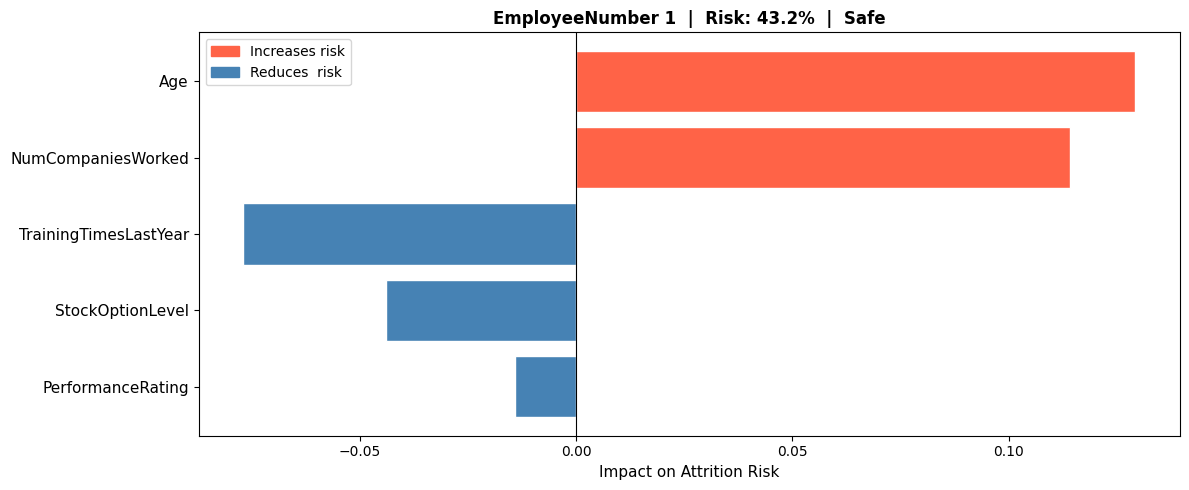

In [33]:
def explain_employee(emp_idx, X_raw_df, results_table, fi_df_loaded):
    """Print and plot the top-5 feature contributions for one employee."""
    row    = results_table.iloc[emp_idx]
    risk   = row['Risk_%']
    status = row['Status']

    id_col = next(
        (c for c in ['EmployeeNumber', 'Name', 'ID'] if c in results_table.columns),
        None
    )
    label = f"{id_col} {str(row[id_col])}" if id_col else f"Employee #{emp_idx}"

    emp_vals  = X_raw_df.iloc[emp_idx]
    pop_means = X_raw_df.mean()

    top_feats = [f for f in fi_df_loaded['Feature'].tolist()
                 if f in emp_vals.index][:10]

    diff = pd.DataFrame({
        'Feature':    top_feats,
        'Employee':   [emp_vals[f] for f in top_feats],
        'Average':    [pop_means[f] for f in top_feats],
        'Importance': [
            fi_df_loaded.loc[
                fi_df_loaded['Feature'] == f, 'Importance'
            ].values[0]
            for f in top_feats
        ]
    })
    diff['Deviation'] = diff['Employee'] - diff['Average']
    diff['Impact']    = diff['Deviation'] * diff['Importance']
    diff = diff.reindex(
        diff['Impact'].abs().sort_values(ascending=False).index
    )

    print('\nTop 5 Reasons (vs company average):')
    for _, r in diff.head(5).iterrows():
        direction = (
            'ABOVE avg — increases risk'
            if r['Deviation'] > 0
            else 'BELOW avg — lowers  risk'
        )
        print(f"  * {r['Feature']:<28}  {direction}")
        print(f"    Value={r['Employee']:.2f}  Avg={r['Average']:.2f}"
              f"  Impact={r['Impact']:+.3f}")

    # Waterfall chart
    top5 = diff.head(5)
    plt.figure(figsize=(12, 5))
    plt.barh(
        range(len(top5)), top5['Impact'],
        color=['tomato' if v > 0 else 'steelblue' for v in top5['Impact']],
        edgecolor='white'
    )
    plt.yticks(range(len(top5)), top5['Feature'], fontsize=11)
    plt.xlabel('Impact on Attrition Risk', fontsize=11)
    plt.title(
        f'{label}  |  Risk: {risk:.1f}%  |  {status}',
        fontsize=12, fontweight='bold'
    )
    plt.axvline(x=0, color='black', linewidth=0.8)
    plt.legend(handles=[
        mpatches.Patch(color='tomato',    label='Increases risk'),
        mpatches.Patch(color='steelblue', label='Reduces  risk')
    ])
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()
    print('=' * 65)


# Change index to explain any employee (0 = highest risk)
EMPLOYEE_INDEX = 0
explain_employee(EMPLOYEE_INDEX, X_raw, results_table, fi_df_loaded)


## 2.10 XAI — Explain Top 5 High-Risk Employees


Top 5 Reasons (vs company average):
  * Age                           BELOW avg — lowers  risk
    Value=21.00  Avg=36.94  Impact=-0.507
  * NumCompaniesWorked            BELOW avg — lowers  risk
    Value=1.00  Avg=3.89  Impact=-0.080
  * StockOptionLevel              BELOW avg — lowers  risk
    Value=0.00  Avg=0.80  Impact=-0.044
  * JobLevel                      BELOW avg — lowers  risk
    Value=1.00  Avg=2.06  Impact=-0.034
  * TrainingTimesLastYear         BELOW avg — lowers  risk
    Value=2.00  Avg=2.80  Impact=-0.022


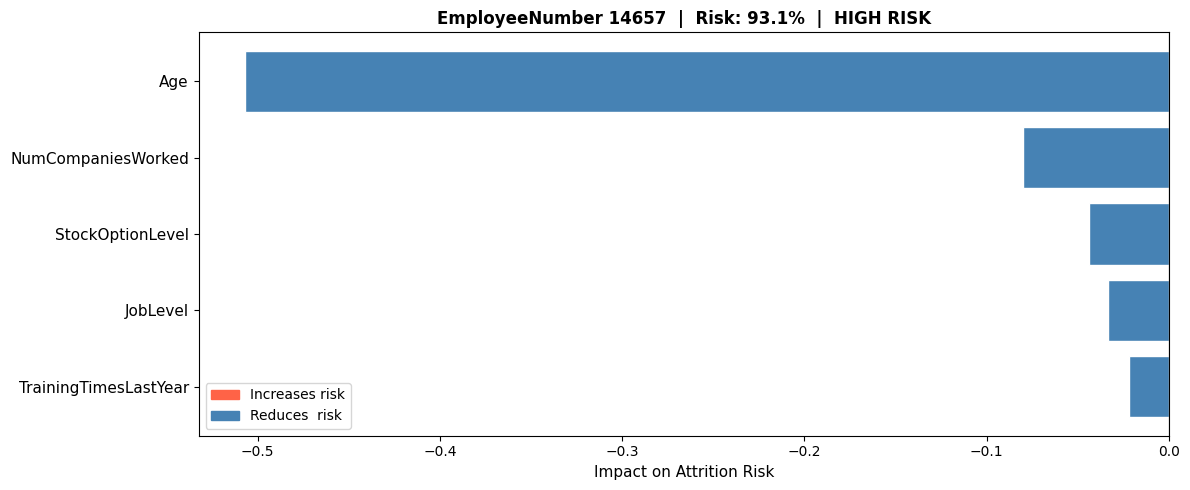



Top 5 Reasons (vs company average):
  * Age                           BELOW avg — lowers  risk
    Value=21.00  Avg=36.94  Impact=-0.507
  * NumCompaniesWorked            BELOW avg — lowers  risk
    Value=1.00  Avg=3.89  Impact=-0.080
  * StockOptionLevel              BELOW avg — lowers  risk
    Value=0.00  Avg=0.80  Impact=-0.044
  * JobLevel                      BELOW avg — lowers  risk
    Value=1.00  Avg=2.06  Impact=-0.034
  * TrainingTimesLastYear         BELOW avg — lowers  risk
    Value=2.00  Avg=2.80  Impact=-0.022


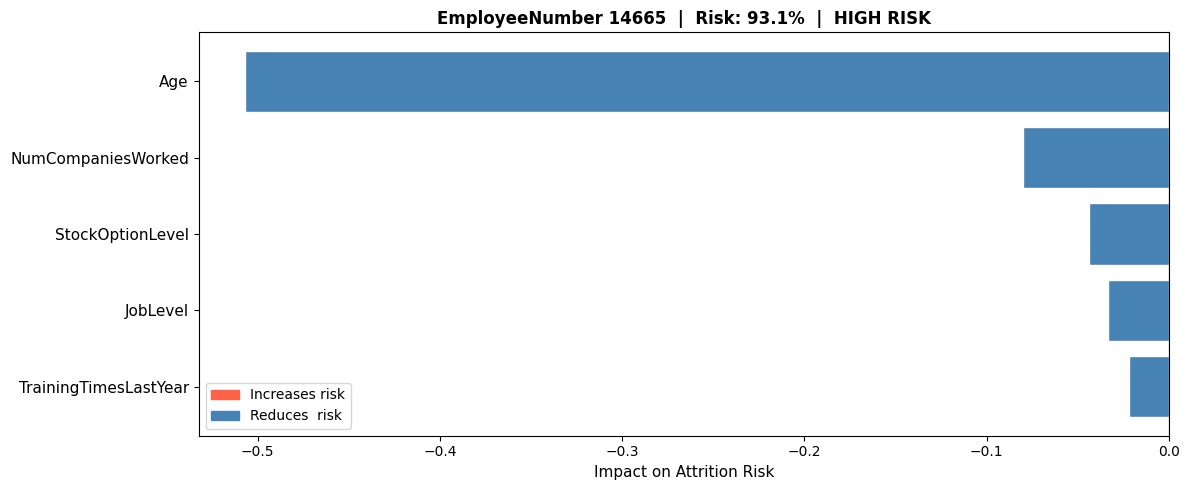



Top 5 Reasons (vs company average):
  * Age                           BELOW avg — lowers  risk
    Value=21.00  Avg=36.94  Impact=-0.507
  * NumCompaniesWorked            BELOW avg — lowers  risk
    Value=1.00  Avg=3.89  Impact=-0.080
  * StockOptionLevel              BELOW avg — lowers  risk
    Value=0.00  Avg=0.80  Impact=-0.044
  * JobLevel                      BELOW avg — lowers  risk
    Value=1.00  Avg=2.06  Impact=-0.034
  * TrainingTimesLastYear         BELOW avg — lowers  risk
    Value=2.00  Avg=2.80  Impact=-0.022


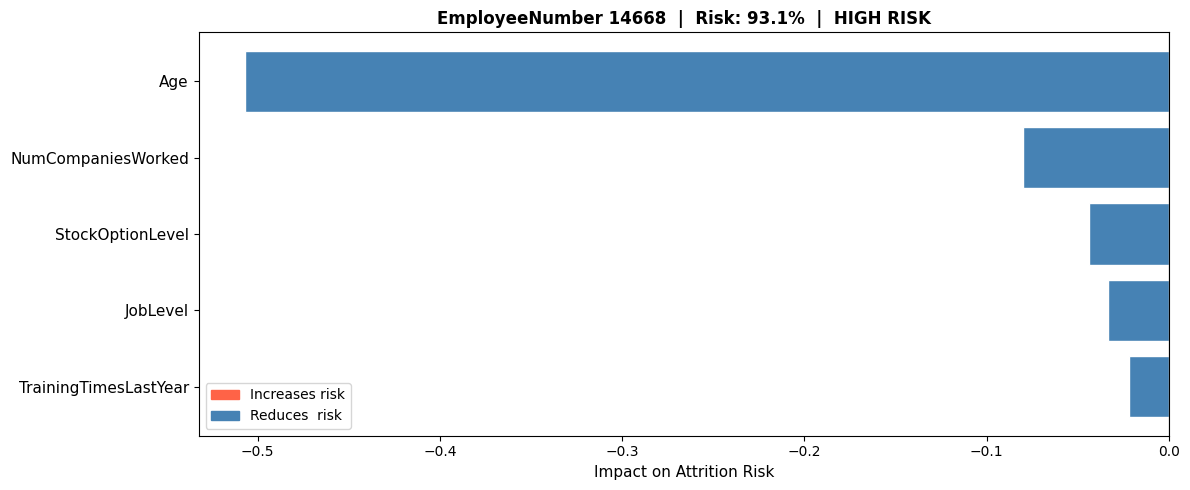



Top 5 Reasons (vs company average):
  * Age                           BELOW avg — lowers  risk
    Value=21.00  Avg=36.94  Impact=-0.507
  * NumCompaniesWorked            ABOVE avg — increases risk
    Value=9.00  Avg=3.89  Impact=+0.142
  * PerformanceRating             ABOVE avg — increases risk
    Value=4.00  Avg=3.16  Impact=+0.077
  * TrainingTimesLastYear         BELOW avg — lowers  risk
    Value=0.00  Avg=2.80  Impact=-0.077
  * StockOptionLevel              BELOW avg — lowers  risk
    Value=0.00  Avg=0.80  Impact=-0.044


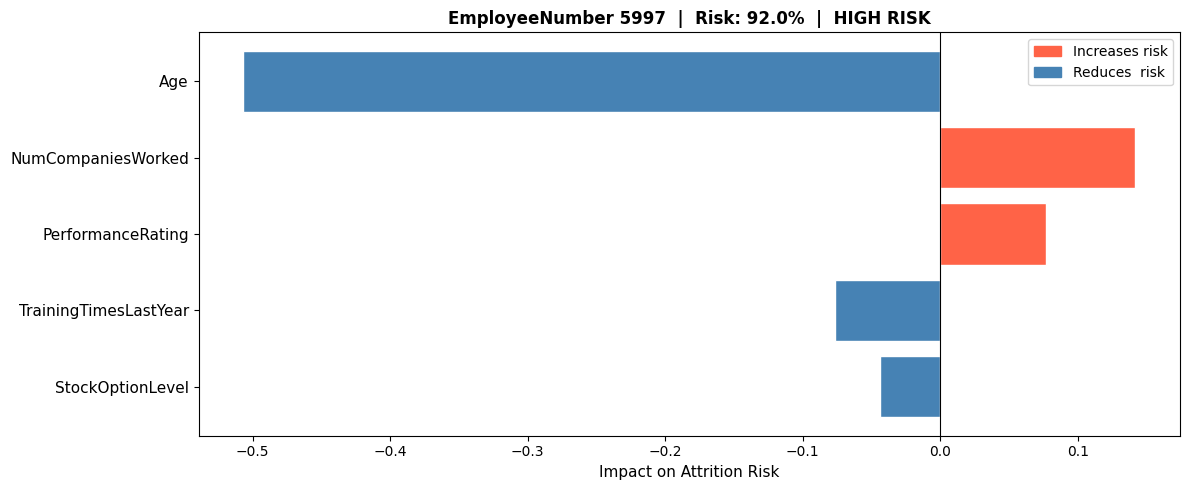



Top 5 Reasons (vs company average):
  * Age                           BELOW avg — lowers  risk
    Value=21.00  Avg=36.94  Impact=-0.507
  * NumCompaniesWorked            ABOVE avg — increases risk
    Value=9.00  Avg=3.89  Impact=+0.142
  * PerformanceRating             ABOVE avg — increases risk
    Value=4.00  Avg=3.16  Impact=+0.077
  * TrainingTimesLastYear         BELOW avg — lowers  risk
    Value=0.00  Avg=2.80  Impact=-0.077
  * StockOptionLevel              BELOW avg — lowers  risk
    Value=0.00  Avg=0.80  Impact=-0.044


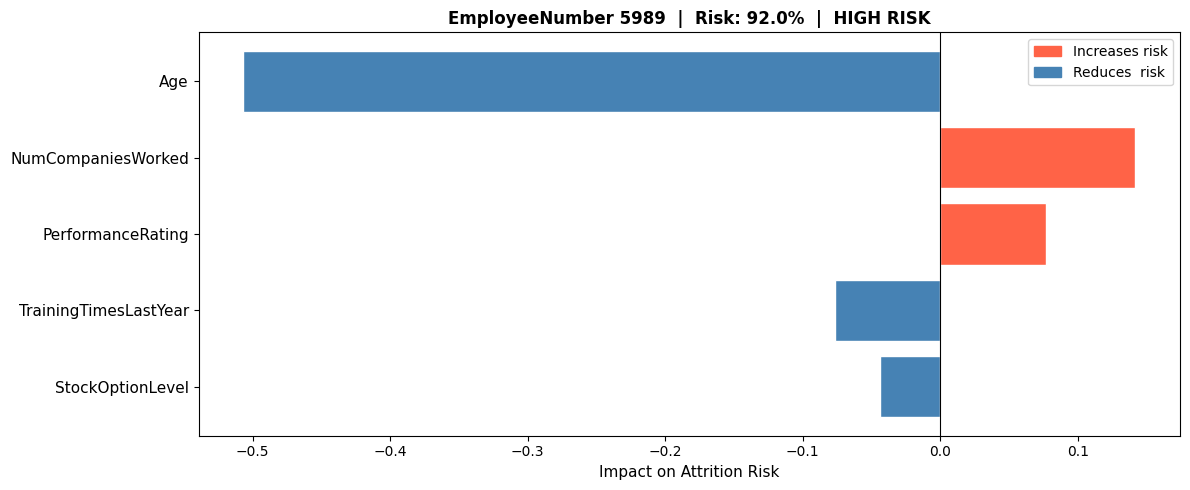

In [34]:
top5_idx = (
    results_table
    .sort_values('Risk_%', ascending=False)
    .head(5)
    .index
    .tolist()
)

for idx in top5_idx:
    explain_employee(idx, X_raw, results_table, fi_df_loaded)
    print()


## 2.10b XAI — Local Feature Contribution per Employee

LOCAL XAI — Top-3 Risk Drivers per Employee
(Contribution > 0 raises risk, < 0 lowers risk)

Rank #1  ─────────────────────────────────────────────────────────────────
  LOCAL XAI  |  EmployeeNumber 14657  |  Risk: 93.1%  |  HIGH RISK
─────────────────────────────────────────────────────────────────
  Feature                          Value       Avg    Contribution
  ----------------------------  --------  --------  --------------
  MonthlyRate                   25308.00  14304.29     +220.8743  ▲ risk
  Application ID                11645.00   2283.87     +160.9771  ▲ risk
  DailyRate                       251.00    801.83      -14.3989  ▼ risk



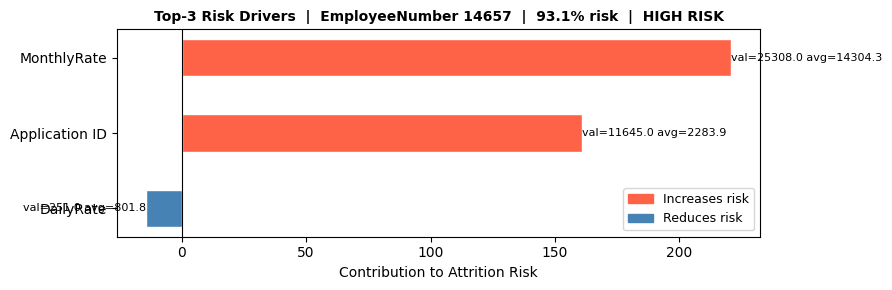

Rank #2  ─────────────────────────────────────────────────────────────────
  LOCAL XAI  |  EmployeeNumber 14665  |  Risk: 93.1%  |  HIGH RISK
─────────────────────────────────────────────────────────────────
  Feature                          Value       Avg    Contribution
  ----------------------------  --------  --------  --------------
  MonthlyRate                   25308.00  14304.29     +220.8743  ▲ risk
  Application ID                11648.00   2283.87     +161.0287  ▲ risk
  DailyRate                       251.00    801.83      -14.3989  ▼ risk



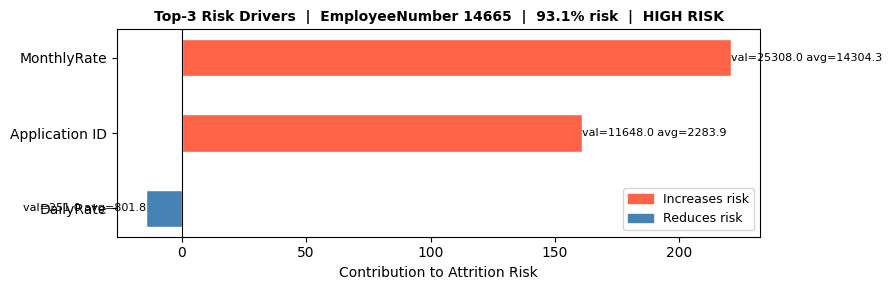

Rank #3  ─────────────────────────────────────────────────────────────────
  LOCAL XAI  |  EmployeeNumber 14668  |  Risk: 93.1%  |  HIGH RISK
─────────────────────────────────────────────────────────────────
  Feature                          Value       Avg    Contribution
  ----------------------------  --------  --------  --------------
  MonthlyRate                   25308.00  14304.29     +220.8743  ▲ risk
  Application ID                11651.00   2283.87     +161.0803  ▲ risk
  DailyRate                       251.00    801.83      -14.3989  ▼ risk



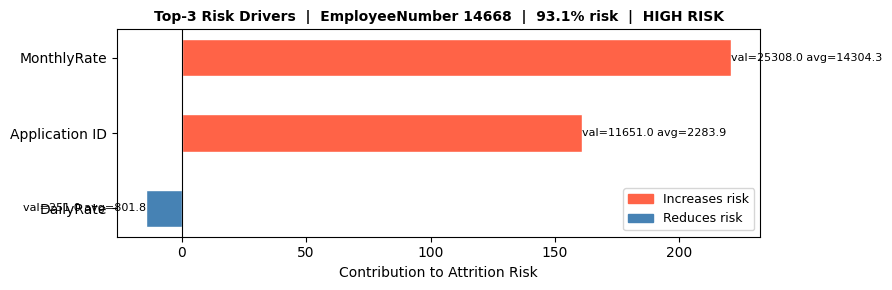

Rank #4  ─────────────────────────────────────────────────────────────────
  LOCAL XAI  |  EmployeeNumber 5997  |  Risk: 92.0%  |  HIGH RISK
─────────────────────────────────────────────────────────────────
  Feature                          Value       Avg    Contribution
  ----------------------------  --------  --------  --------------
  MonthlyRate                   25422.00  14304.29     +223.1626  ▲ risk
  Application ID                 4761.00   2283.87      +42.5975  ▲ risk
  DailyRate                       156.00    801.83      -16.8822  ▼ risk

Rank #5  ─────────────────────────────────────────────────────────────────
  LOCAL XAI  |  EmployeeNumber 5989  |  Risk: 92.0%  |  HIGH RISK
─────────────────────────────────────────────────────────────────
  Feature                          Value       Avg    Contribution
  ----------------------------  --------  --------  --------------
  MonthlyRate                   25422.00  14304.29     +223.1626  ▲ risk
  Application ID         

In [35]:
def local_xai_top3(emp_idx, X_raw_df, results_table, fi_df_loaded,
                    print_output=True, plot=True):
    """
    Explain a single employee's prediction with the top-3 feature drivers.
    Returns contrib_df with columns:
      Feature, Employee, Average, Importance, Deviation, Contribution
    """
    row    = results_table.iloc[emp_idx]
    risk   = row['Risk_%']
    status = row['Status']

    id_col = next(
        (c for c in ['EmployeeNumber', 'Name', 'ID']
         if c in results_table.columns),
        None
    )
    label = (
        f"{id_col} {str(row[id_col])}"
        if id_col else f"Employee #{emp_idx}"
    )

    valid_feats    = [f for f in fi_df_loaded['Feature']
                      if f in X_raw_df.columns]
    emp_vals       = X_raw_df.iloc[emp_idx][valid_feats]
    pop_means      = X_raw_df[valid_feats].mean()
    importance_map = fi_df_loaded.set_index('Feature')['Importance'].to_dict()

    contrib_df = pd.DataFrame({
        'Feature':    valid_feats,
        'Employee':   emp_vals.values,
        'Average':    pop_means.values,
        'Importance': [importance_map.get(f, 0) for f in valid_feats],
    })
    contrib_df['Deviation']    = contrib_df['Employee'] - contrib_df['Average']
    contrib_df['Contribution'] = (
        contrib_df['Deviation'] * contrib_df['Importance']
    )
    contrib_df = contrib_df.reindex(
        contrib_df['Contribution'].abs().sort_values(ascending=False).index
    ).reset_index(drop=True)
    top3 = contrib_df.head(3)

    if print_output:
        print('─' * 65)
        print(f'  LOCAL XAI  |  {label}  |  Risk: {risk:.1f}%  |  {status}')
        print('─' * 65)
        print(f'  {"Feature":<28}  {"Value":>8}  {"Avg":>8}  {"Contribution":>14}')
        print(f'  {"-"*28}  {"-"*8}  {"-"*8}  {"-"*14}')
        for _, r in top3.iterrows():
            direction = '▲ risk' if r['Contribution'] > 0 else '▼ risk'
            print(f"  {r['Feature']:<28}  {r['Employee']:>8.2f}  "
                  f"{r['Average']:>8.2f}  "
                  f"{r['Contribution']:>+12.4f}  {direction}")
        print()

    if plot:
        colors = ['tomato' if v > 0 else 'steelblue'
                  for v in top3['Contribution']]
        fig, ax = plt.subplots(figsize=(9, 3))
        bars = ax.barh(top3['Feature'], top3['Contribution'],
                       color=colors, edgecolor='white', height=0.5)
        ax.axvline(0, color='black', linewidth=0.8)
        ax.set_xlabel('Contribution to Attrition Risk', fontsize=10)
        ax.set_title(
            f'Top-3 Risk Drivers  |  {label}  |  {risk:.1f}% risk  |  {status}',
            fontsize=10, fontweight='bold'
        )
        for bar, (_, r) in zip(bars, top3.iterrows()):
            offset = 0.0002 if r['Contribution'] >= 0 else -0.0002
            align  = 'left' if r['Contribution'] >= 0 else 'right'
            ax.text(
                bar.get_width() + offset,
                bar.get_y() + bar.get_height() / 2,
                f"val={r['Employee']:.1f} avg={r['Average']:.1f}",
                va='center', ha=align, fontsize=8
            )
        ax.legend(handles=[
            mpatches.Patch(color='tomato',    label='Increases risk'),
            mpatches.Patch(color='steelblue', label='Reduces risk'),
        ], fontsize=9)
        ax.invert_yaxis()
        plt.tight_layout()
        plt.show()

    return contrib_df


# Run local XAI on the top 10 highest-risk employees
top10_idx = (
    results_table
    .sort_values('Risk_%', ascending=False)
    .head(10)
    .index
    .tolist()
)

print('LOCAL XAI — Top-3 Risk Drivers per Employee')
print('(Contribution > 0 raises risk, < 0 lowers risk)\n')

for i, idx in enumerate(top10_idx, start=1):
    print(f'Rank #{i}', end='  ')
    local_xai_top3(idx, X_raw, results_table, fi_df_loaded,
                   print_output=True, plot=(i <= 3))

# Bulk summary: top-1 driver per high-risk employee
high_risk_idx  = results_table[results_table['Prediction'] == 1].index.tolist()
summary_rows   = []
for idx in high_risk_idx:
    contrib = local_xai_top3(idx, X_raw, results_table, fi_df_loaded,
                              print_output=False, plot=False)
    top1 = contrib.iloc[0]
    row  = results_table.iloc[idx]
    id_col = next(
        (c for c in ['EmployeeNumber', 'Name', 'ID']
         if c in results_table.columns),
        None
    )
    summary_rows.append({
        'Employee':       row[id_col] if id_col else idx,
        'Risk_%':         row['Risk_%'],
        'Top_Driver':     top1['Feature'],
        'Employee_Value': round(top1['Employee'], 2),
        'Population_Avg': round(top1['Average'],  2),
        'Contribution':   round(top1['Contribution'], 4),
        'Direction':      '▲ risk' if top1['Contribution'] > 0 else '▼ risk',
    })

xai_summary = (
    pd.DataFrame(summary_rows)
    .sort_values('Risk_%', ascending=False)
)
print('\n── Summary: Primary Risk Driver per HIGH RISK Employee ──')
print(xai_summary.to_string(index=False))

xai_summary.to_csv('hr_xai_local_summary.csv', index=False)
print('\nSaved: hr_xai_local_summary.csv')


## 2.11 Final Dashboard Summary

In [36]:
print('=' * 65)
print('  HR DECISION SUPPORT SYSTEM — FINAL REPORT')
print('=' * 65)

total = len(results_table)
high  = (results_table['Prediction'] == 1).sum()
safe  = total - high

print(f'  Total Employees  : {total}')
print(f'  HIGH RISK        : {high}   ({high/total*100:.1f}%)')
print(f'  Safe             : {safe}   ({safe/total*100:.1f}%)')
print(f'  Average Risk     : {results_table["Risk_%"].mean():.1f}%')
print(f'  Risk Threshold   : {RISK_THRESHOLD}')
print(f'\n  Best Model       : {best_model_name}')
print(f'  Model Accuracy   : {ml_results[best_model_name]["acc"]*100:.2f}%')
print(f'  Model AUC        : {ml_results[best_model_name]["auc"]*100:.2f}%')

if 'Department' in results_table.columns and 'dept_stats' in dir():
    worst = dept_stats.iloc[0]['Department']
    print(f'\n  Highest Risk Dept: {worst}')

print('\n  Top 5 Global Risk Factors (XAI):')
for i, row in fi_df_loaded.head(5).iterrows():
    print(f'    {i+1}. {row["Feature"]}')

print('=' * 65)
print('  ANALYSIS COMPLETE')
print('=' * 65)


  HR DECISION SUPPORT SYSTEM — FINAL REPORT
  Total Employees  : 23436
  HIGH RISK        : 849   (3.6%)
  Safe             : 22587   (96.4%)
  Average Risk     : 11.1%
  Risk Threshold   : 0.43802955459330734

  Best Model       : XGBoost Classifier
  Model Accuracy   : 98.74%
  Model AUC        : 99.82%

  Highest Risk Dept: Human Resources

  Top 5 Global Risk Factors (XAI):
    1. PerformanceRating
    2. EducationField
    3. OverTime
    4. StockOptionLevel
    5. Age
  ANALYSIS COMPLETE


## 2.12 Export Reports

In [37]:
# All predictions
results_table.to_csv('hr_all_predictions.csv', index=False)
print('Saved: hr_all_predictions.csv')

# Top 50 highest-risk employees
results_table.sort_values('Risk_%', ascending=False).head(50).to_csv(
    'hr_top50_risk.csv', index=False)
print('Saved: hr_top50_risk.csv')

# XAI feature importance
fi_df_loaded.to_csv('hr_xai_factors.csv', index=False)
print('Saved: hr_xai_factors.csv')

print('\nAll reports exported successfully.')


Saved: hr_all_predictions.csv
Saved: hr_top50_risk.csv
Saved: hr_xai_factors.csv

All reports exported successfully.


---
# PART 3 — RAG AI Consultant Pipeline
### Policy-Grounded Retention Recommendations via LangChain + GPT-4o
---

## 3.1 Install RAG Dependencies

In [2]:
!pip install -q langchain==0.2.17 langchain-core==0.2.43 langchain-community==0.2.19 langchain-groq==0.1.9 langchain-chroma==0.1.4 chromadb==0.5.3 pypdf sentence-transformers

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
langchain-classic 1.0.8 requires langchain-core<2.0.0,>=1.4.4, but you have langchain-core 0.2.43 which is incompatible.
langchain-classic 1.0.8 requires langchain-text-splitters<2.0.0,>=1.1.2, but you have langchain-text-splitters 0.2.4 which is incompatible.
langgraph-sdk 0.4.2 requires langchain-core<2,>=1.4.0, but you have langchain-core 0.2.43 which is incompatible.
langgraph-prebuilt 1.1.0 requires langchain-core>=1.3.1, but you have langchain-core 0.2.43 which is incompatible.
langgraph 1.2.4 requires langchain-core<2,>=1.4.0, but you have langchain-core 0.2.43 which is incompatible.


In [3]:
# =============================================================================
# §3.1 RAG DEPENDENCY INSTALLATION — GROQ MIGRATION (LOCKED ENVIRONMENT)
# =============================================================================
import subprocess, sys, os
from pathlib import Path

def _pip(args):
    subprocess.check_call([sys.executable, "-m", "pip"] + args)

print("⚡ Purging conflicting packages...")
_pip(["uninstall", "-y", "langchain", "langchain-core", "langchain-community",
      "langchain-openai", "langchain-text-splitters", "langchain-chroma",
      "chromadb", "openai", "tiktoken"])

print("\n⚡ Installing pinned Groq + LangChain ecosystem...")
_pip(["install", "-q",
      "langchain==0.3.25",
      "langchain-core==0.3.58",
      "langchain-community==0.3.24",
      "langchain-groq==0.2.4",
      "langchain-chroma==0.2.4",
      "langchain-huggingface>=0.1.2,<0.2.0",
      "chromadb==0.6.3",
      "pypdf>=4.2.0,<5.0.0",
      "sentence-transformers>=2.7.0,<3.0.0"])

print("\n✅ Pinned Groq Edition installed. A Kernel restart is required before §3.2.")


⚡ Purging conflicting packages...

⚡ Installing pinned Groq + LangChain ecosystem...


CalledProcessError: Command '['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'langchain==0.2.17', 'langchain-core==0.2.43', 'langchain-community==0.2.19', 'langchain-groq==0.1.9', 'langchain-chroma==0.1.4', 'chromadb==0.5.5', 'pypdf>=4.2.0,<5.0.0', 'sentence-transformers>=2.7.0,<3.0.0']' returned non-zero exit status 1.

## 3.2 RAG Setup — Load PDF, Embed, Build Vector Store

In [2]:
# =============================================================================
# §3.2 CODE ENGINE INITIALIZATION (EXECUTE AFTER KERNEL RESTART)
# =============================================================================
import os
from pathlib import Path
from google.colab import userdata

try:
    from langchain_community.document_loaders import PyPDFLoader
    from langchain.text_splitter import RecursiveCharacterTextSplitter
    from langchain_huggingface import HuggingFaceEmbeddings
    from langchain_chroma import Chroma
    from langchain_groq import ChatGroq
    from langchain.chains import RetrievalQA
    from langchain.prompts import PromptTemplate
    _RAG_AVAILABLE = True
except ImportError as _ie:
    _RAG_AVAILABLE = False
    _RAG_IMPORT_ERROR = str(_ie)

# ── Configuration ─────────────────────────────────────────────────────────────
PDF_PATH       = "./data_docs/hr_policy_manual.pdf"
CHROMA_PERSIST = "./data_docs/chroma_hr_policy"
LLM_MODEL      = "llama3-70b-8192"
EMBED_MODEL    = "all-MiniLM-L6-v2"
RETRIEVER_K    = 6

Path("./data_docs").mkdir(parents=True, exist_ok=True)
if not Path(PDF_PATH).exists():
    raise FileNotFoundError(f"Missing manual at: {PDF_PATH}")

if _RAG_AVAILABLE:
    print("⚡ Loading PDF and chunking...")
    loader    = PyPDFLoader(PDF_PATH)
    raw_pages = loader.load()
    splitter  = RecursiveCharacterTextSplitter(
        chunk_size=600, chunk_overlap=120,
        separators=["\n\n", "\n", ".", "---", " "]
    )
    chunks = splitter.split_documents(raw_pages)
    print(f"   Pages: {len(raw_pages)} | Chunks: {len(chunks)}")

    print("⚡ Building/Loading Chroma vector store (HuggingFace embeddings)...")
    embeddings  = HuggingFaceEmbeddings(model_name=EMBED_MODEL)
    chroma_dir  = Path(CHROMA_PERSIST)
    if chroma_dir.exists() and any(chroma_dir.iterdir()):
        vectorstore = Chroma(persist_directory=CHROMA_PERSIST, embedding_function=embeddings)
    else:
        vectorstore = Chroma.from_documents(
            documents=chunks, embedding=embeddings, persist_directory=CHROMA_PERSIST
        )
    retriever = vectorstore.as_retriever(search_type="mmr", search_kwargs={"k": RETRIEVER_K})
    print(f"   Vector store ready — {vectorstore._collection.count()} chunks indexed.")

    HR_CONSULTANT_PROMPT = PromptTemplate(
        input_variables=["context", "question"],
        template=(
            "You are an AI Executive HR Consultant specializing in employee retention.\n"
            "You have been provided with the company\'s official Corporate HR Policy Manual\n"
            "as your sole knowledge base. Analyze the high-risk employee profile and prescribe\n"
            "concrete, policy-grounded retention strategies.\n\n"
            "MANDATORY RULES:\n"
            "1. Every recommendation MUST cite the exact Article, Section, and Clause.\n"
            "2. Be specific — mention exact thresholds, timelines, and compensation bands.\n"
            "3. Structure output: IMMEDIATE (30 days) | SHORT-TERM (1-6 mo) | LONG-TERM (6-12 mo).\n"
            "4. Do NOT invent policies. If the manual does not cover a factor, say so.\n\n"
            "HR POLICY MANUAL CONTEXT:\n"
            "────────────────────────────────────────────────────────────────────────\n"
            "{context}\n"
            "────────────────────────────────────────────────────────────────────────\n\n"
            "EMPLOYEE PROFILE AND RISK ANALYSIS:\n"
            "{question}\n\n"
            "RETENTION STRATEGY REPORT:"
        ),
    )

    groq_api_key = userdata.get("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")
    llm = ChatGroq(model=LLM_MODEL, temperature=0.2, groq_api_key=groq_api_key)
    rag_chain = RetrievalQA.from_chain_type(
        llm=llm, chain_type="stuff", retriever=retriever,
        chain_type_kwargs={"prompt": HR_CONSULTANT_PROMPT},
        return_source_documents=True,
    )
    print("✅ Groq RAG chain (llama3-70b-8192) assembled successfully!")
else:
    print(f"❌ RAG skipped — Import Error: {_RAG_IMPORT_ERROR}")


❌ RAG skipped — Import Error: No module named 'langchain_community'


## 3.3 RAG Helper — Build Employee Context String

In [ ]:
def build_employee_context(
    emp_idx: int,
    results_table,
    new_df,
    risk_probability: float,
    opt_threshold: float,
) -> str:
    """
    Build a structured employee profile string for the RAG query.

    CRITICAL — .loc ALIGNMENT FIX:
    results_table may be sorted/filtered (e.g. .sort_values("Risk_%")),
    so its positional index no longer matches new_df's positional index.
    We resolve the *actual* DataFrame index label from results_table first,
    then use .loc[actual_index] on BOTH DataFrames — guaranteeing that every
    feature value retrieved belongs to the same physical employee row.

    Parameters
    ----------
    emp_idx       : integer position inside results_table (0 = highest risk
                    after sorting, NOT the raw DataFrame index label)
    results_table : DataFrame from §2.5 — may be sorted or filtered
    new_df        : raw uploaded DataFrame from §2.2 — original order
    risk_probability : raw predict_proba value (0–100 float)
    opt_threshold    : float 0–1 (from artifact['threshold'])
    """
    # ── Step 1: resolve the true DataFrame index label ───────────────────
    # results_table.index[emp_idx] gives the LABEL of row at position emp_idx.
    # This is the original row number from new_df before any sorting occurred.
    actual_index = results_table.index[emp_idx]

    # ── Step 2: pull risk/status from results_table using .loc ──────────
    risk_row = results_table.loc[actual_index]
    risk_pct = float(risk_row.get("Risk_%", risk_probability))
    status   = risk_row.get("Status", "HIGH RISK")

    # ── Step 3: safe column getter — reads new_df via .loc[actual_index] ─
    # This guarantees: the same physical employee row in both DataFrames.
    def _get(col, default="N/A"):
        if col not in new_df.columns:
            return default
        val = new_df.loc[actual_index, col]
        return default if str(val) in ("nan", "None", "NaN", "") else val

    # ── Step 4: extract all feature values ───────────────────────────────
    overtime    = _get("OverTime")
    job_sat     = _get("JobSatisfaction")
    env_sat     = _get("EnvironmentSatisfaction")
    rel_sat     = _get("RelationshipSatisfaction")
    wlb         = _get("WorkLifeBalance")
    yrs_promo   = _get("YearsSinceLastPromotion")
    yrs_company = _get("YearsAtCompany")
    yrs_role    = _get("YearsInCurrentRole")
    total_yrs   = _get("TotalWorkingYears")
    income      = _get("MonthlyIncome")
    job_level   = _get("JobLevel")
    job_role    = _get("JobRole")
    department  = _get("Department")
    training    = _get("TrainingTimesLastYear")
    distance    = _get("DistanceFromHome")
    perf        = _get("PerformanceRating")
    stock       = _get("StockOptionLevel")
    n_companies = _get("NumCompaniesWorked")

    # ── Step 5: employee ID ───────────────────────────────────────────────
    id_col = next(
        (c for c in ["EmployeeNumber", "Name", "ID"] if c in new_df.columns),
        None,
    )
    emp_id = f"{id_col} {_get(id_col)}" if id_col else f"Employee (index={actual_index})"

    # ── Step 6: automated policy trigger flags ────────────────────────────
    # These mirror the exact thresholds stated in the HR Policy Manual.
    try:
        yrs_promo_f = float(str(yrs_promo).replace("N/A", "0") or 0)
        training_f  = float(str(training).replace("N/A", "99") or 99)
        ot_str      = str(overtime).strip().lower()

        # Article II §2.3.1: stagnation trigger ≥ 3 years without promotion
        promo_flag = (
            "CRITICAL — triggers Article II §2.3 Stagnation Intervention Protocol"
            if yrs_promo_f >= 3
            else f"OK ({yrs_promo_f:.0f} yr — below 3-yr threshold)"
        )
        # Article IV §4.8: development engagement risk < 3 training sessions
        train_flag = (
            "ALERT — triggers Article IV §4.8 Development Engagement Risk"
            if training_f < 3
            else f"OK ({training_f:.0f} sessions — above minimum)"
        )
        # Article I §1.4.1: burnout prevention if overtime active
        ot_flag = (
            "CRITICAL — triggers Article I §1.4 Burnout Prevention Program"
            if ot_str == "yes"
            else "No overtime flag"
        )
    except (ValueError, TypeError):
        promo_flag = train_flag = ot_flag = "N/A (data parse error)"

    # ── Step 7: compose context string ───────────────────────────────────
    return f"""
EMPLOYEE IDENTIFICATION:
  DataFrame Index  : {actual_index}  (original row label — .loc aligned)
  Employee ID      : {emp_id}
  Job Role         : {job_role}
  Department       : {department}
  Job Level        : {job_level}

ATTRITION RISK ASSESSMENT:
  Predicted Risk    : {risk_pct:.1f}%  [{status}]
  Raw Probability   : {risk_pct / 100:.4f}
  Optimal Threshold : {opt_threshold * 100:.0f}%  (F1-maximised, §1.11)
  Risk Excess       : +{risk_pct - opt_threshold * 100:.1f} pp above decision boundary

WORKLOAD & OVERTIME:
  OverTime             : {overtime}  [{ot_flag}]
  Distance From Home   : {distance} km

SATISFACTION SCORES  (1 = Low, 4 = High):
  Job Satisfaction     : {job_sat}
  Environment          : {env_sat}
  Relationship         : {rel_sat}
  Work-Life Balance    : {wlb}

CAREER PROGRESSION:
  Years at Company           : {yrs_company}
  Years in Current Role      : {yrs_role}
  Years Since Last Promotion : {yrs_promo}  [{promo_flag}]
  Total Working Years        : {total_yrs}
  Number of Companies Worked : {n_companies}

COMPENSATION & REWARDS:
  Monthly Income      : ${income}
  Stock Option Level  : {stock}  (0=None, 1=Strong, 2=High, 3=Critical)
  Performance Rating  : {perf}

DEVELOPMENT:
  Training Sessions Last Year : {training}  [{train_flag}]

AUTOMATED POLICY TRIGGER SUMMARY:
  Overtime Protocol  : {ot_flag}
  Promotion Protocol : {promo_flag}
  Training Protocol  : {train_flag}

TASK FOR AI HR CONSULTANT:
Analyze the profile above against the Corporate HR Policy Manual.
Output a structured retention plan with three sections:
  IMMEDIATE (within 30 days)
  SHORT-TERM (1–6 months)
  LONG-TERM (6–12 months)
Cite every applicable Article, Section, and Clause explicitly.
State which HR protocols must be automatically triggered right now.
""".strip()


print("build_employee_context() defined — .loc alignment fix applied.")
print(f"  Index resolution: results_table.index[emp_idx] → .loc[actual_index]")
print(f"  Both results_table and new_df are accessed via .loc[actual_index].")


## 3.4 RAG Trigger — Auto-Consult All HIGH-RISK Employees

In [ ]:
def run_rag_for_employee(
    emp_idx: int,
    results_table,
    new_df,
    opt_threshold: float,
    rag_chain,
    print_sources: bool = False,
) -> dict:
    """
    Auto-trigger the RAG AI HR Consultant for one employee.

    CRITICAL — .loc ALIGNMENT FIX propagated here:
    We resolve actual_index = results_table.index[emp_idx] first, then
    use .loc[actual_index] for every lookup in both results_table and new_df.
    This prevents cross-wired rows when results_table has been sorted.

    Parameters
    ----------
    emp_idx       : positional rank inside results_table (0 = highest risk)
    results_table : DataFrame from §2.5 — may be sorted
    new_df        : raw uploaded DataFrame from §2.2 — original order
    opt_threshold : float 0–1 from artifact['threshold']
    rag_chain     : RetrievalQA chain from §3.2
    print_sources : if True, print retrieved PDF page excerpts

    Returns
    -------
    dict with keys: emp_idx, actual_index, emp_id, risk_pct,
                    status, recommendation, sources
    """
    # ── Resolve true index label ─────────────────────────────────────────
    actual_index = results_table.index[emp_idx]
    risk_row     = results_table.loc[actual_index]
    risk_pct     = float(risk_row.get("Risk_%", 0))
    status       = risk_row.get("Status", "")

    # ── Gate: only consult on HIGH RISK employees ─────────────────────────
    if risk_pct < opt_threshold * 100:
        return {
            "emp_idx":        emp_idx,
            "actual_index":   actual_index,
            "risk_pct":       risk_pct,
            "status":         status,
            "recommendation": "[SKIPPED — employee is NOT high risk]",
            "sources":        [],
        }

    # ── Build context using the loc-aligned helper ────────────────────────
    employee_context = build_employee_context(
        emp_idx, results_table, new_df, risk_pct, opt_threshold
    )

    # ── Run RAG chain ─────────────────────────────────────────────────────
    response       = rag_chain.invoke({"query": employee_context})
    recommendation = response["result"]
    source_docs    = response.get("source_documents", [])

    # ── Employee label — also .loc aligned ───────────────────────────────
    id_col = next(
        (c for c in ["EmployeeNumber", "Name", "ID"] if c in new_df.columns),
        None,
    )
    emp_id = (
        f"{id_col} {new_df.loc[actual_index, id_col]}"
        if id_col
        else f"Employee (index={actual_index})"
    )

    # ── Print formatted report ────────────────────────────────────────────
    print("=" * 70)
    print(f"  AI HR CONSULTANT REPORT")
    print(f"  Employee      : {emp_id}")
    print(f"  DataFrame idx : {actual_index}  (positional rank #{emp_idx})")
    print(f"  Risk          : {risk_pct:.1f}%  |  Threshold: {opt_threshold*100:.0f}%  |  {status}")
    print("=" * 70)
    print(recommendation)
    print()

    if print_sources:
        print("── Retrieved Policy Excerpts ─────────────────────────────────────")
        for i, doc in enumerate(source_docs, 1):
            pg = doc.metadata.get("page", "?")
            print(f"  [Excerpt {i} — Page {pg}]")
            print(f"  {doc.page_content[:300].strip()} …")
            print()

    return {
        "emp_idx":        emp_idx,
        "actual_index":   actual_index,
        "emp_id":         emp_id,
        "risk_pct":       risk_pct,
        "status":         status,
        "recommendation": recommendation,
        "sources": [
            {
                "page":    d.metadata.get("page", "?"),
                "excerpt": d.page_content[:300],
            }
            for d in source_docs
        ],
    }


# ─────────────────────────────────────────────────────────────────────────────
# AUTO-RUN: get top-5 HIGH RISK employees by positional rank after sorting
# ─────────────────────────────────────────────────────────────────────────────
# We sort results_table descending and take the first 5 HIGH RISK rows.
# Their positional ranks (0, 1, 2, 3, 4) are passed to run_rag_for_employee,
# which resolves actual_index internally — so no index mismatch can occur.
results_sorted_hr = (
    results_table[results_table["Prediction"] == 1]
    .sort_values("Risk_%", ascending=False)
    .reset_index(drop=False)   # keeps original index as a column named "index"
)

# Re-build a clean positional-rank results view for the RAG loop
# (positional ranks 0..N-1 now map directly to sorted HIGH RISK employees)
results_high_risk_sorted = (
    results_table[results_table["Prediction"] == 1]
    .sort_values("Risk_%", ascending=False)
)

top5_count = min(5, len(results_high_risk_sorted))

print(f"HIGH RISK employees found : {len(results_high_risk_sorted)}")
print(f"Consulting AI on top {top5_count} …\n")

rag_reports = []
for pos_rank in range(top5_count):
    rpt = run_rag_for_employee(
        emp_idx=pos_rank,
        results_table=results_high_risk_sorted,   # already sorted — pos 0 = highest risk
        new_df=new_df,
        opt_threshold=opt_threshold,
        rag_chain=rag_chain,
        print_sources=False,   # set True to see retrieved PDF chunks
    )
    rag_reports.append(rpt)

print(f"\nCompleted {len(rag_reports)} RAG reports.")


## 3.5 RAG — Consult on a Specific Employee

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# §3.5  Consult on a SPECIFIC Employee
# ─────────────────────────────────────────────────────────────────────────────
# QUERY_EMPLOYEE_RANK is the positional rank inside results_high_risk_sorted
# (0 = highest-risk HIGH RISK employee).
# The .loc alignment fix inside run_rag_for_employee ensures the correct
# new_df row is always fetched regardless of sort order.

QUERY_EMPLOYEE_RANK = 0   # change to investigate a different high-risk employee

single_report = run_rag_for_employee(
    emp_idx=QUERY_EMPLOYEE_RANK,
    results_table=results_high_risk_sorted,   # sorted HIGH RISK view
    new_df=new_df,
    opt_threshold=opt_threshold,
    rag_chain=rag_chain,
    print_sources=True,    # show retrieved PDF chunks for transparency
)

# ── Alignment sanity check ────────────────────────────────────────────────
# Confirms that results_table and new_df agree on the same employee.
_ai  = single_report["actual_index"]
_id_col = next(
    (c for c in ["EmployeeNumber", "Name", "ID"] if c in new_df.columns), None
)
if _id_col:
    _rt_id  = results_high_risk_sorted.loc[_ai, _id_col] if _id_col in results_high_risk_sorted.columns else "N/A in results_table"
    _ndf_id = new_df.loc[_ai, _id_col]
    print(f"\n── Alignment check ─────────────────────────────────────────────")
    print(f"  actual_index       : {_ai}")
    print(f"  results_table ID   : {_rt_id}")
    print(f"  new_df ID          : {_ndf_id}")
    match = str(_rt_id) == str(_ndf_id)
    print(f"  IDs match          : {match}  ← must be True")
    if not match:
        print("  ⚠ MISMATCH — investigate index alignment before trusting recommendations.")
else:
    print(f"\nAlignment check: actual_index = {_ai} (no ID column found to cross-check)")


## 3.6 Export RAG Reports to CSV

In [ ]:
rag_export_rows = []
for r in rag_reports:
    rag_export_rows.append({
        "Positional_Rank":    r["emp_idx"],
        "DataFrame_Index":    r.get("actual_index", "N/A"),
        "Employee":           r.get("emp_id", r["emp_idx"]),
        "Risk_%":             r["risk_pct"],
        "Status":             r["status"],
        "AI_Recommendation":  r["recommendation"],
        "Sources_Pages":      ", ".join(
            str(s["page"]) for s in r.get("sources", [])
        ),
    })

rag_df = pd.DataFrame(rag_export_rows)
rag_df.to_csv("hr_rag_retention_reports.csv", index=False)
print(f"Saved: hr_rag_retention_reports.csv  ({len(rag_df)} reports)")
print(f"Columns: {list(rag_df.columns)}")
rag_df[["Positional_Rank", "DataFrame_Index", "Employee", "Risk_%", "Status"]].head()


---
## Project Summary

| Part | Steps | Description |
|------|-------|-------------|
| **PART 1** | 1.1 – 1.13 | Data cleaning, feature engineering, model training, artifact saving |
| **PART 2** | 2.1 – 2.12 | Upload validation, imputation, prediction, XAI, export |

### Production Enhancements Applied
1. **Separate pipeline artifacts** — `scaler.pkl`, `encoder.pkl`, `imputer.pkl` saved alongside `hr_model.pkl` (§1.13)
2. **No leakage in PART 2** — §2.1 loads from `.pkl` files; §2.4 calls `.transform()` only — `.fit()` never called on new data
3. **Optimised threshold enforced** — §2.5 uses `predict_proba()` + threshold from `precision_recall_curve` (not `model.predict()`)
4. **Local XAI (§2.10b)** — per-employee Top-3 feature contributions; bulk summary CSV `hr_xai_local_summary.csv`

### Previous Engineering Highlights
- Encoder leakage fixed — `LabelEncoder` fit on `X_train` only
- Split → Encode → Scale → SMOTE pipeline order
- 5-metric evaluation — Accuracy, Precision, Recall, F1, ROC-AUC
- Threshold optimization via `precision_recall_curve()`
- Artifact versioning — `model_version` + `training_timestamp`